# 3팀 · AI 기반 군수품 도면 판독 및 품질검사

**출처:** 본선1일차 추출 팀 자료 · **핵심 기능:** 검사요건 정리와 품질검사 결과의 이상 항목 점검.

이 노트북은 발표 주제와 연결된 데이터 분석 실습입니다. 입력 CSV는 연습용 합성데이터이며 실제 부대·인원·작전 자료가 아닙니다. 기본 입력은 `../../data/3팀_품질검사데이터.csv` 입니다.

**사용 순서**
1. `0. 준비` 셀을 실행해 분석 라이브러리를 준비합니다.
2. `1. 데이터 불러오기`에서 기본 CSV 경로를 확인하거나 실습용 파일을 업로드합니다.
3. `2. 공통 설정`에서 컬럼 유형과 분석 범위를 확인합니다.
4. 필요한 시각화·군집·예측 셀을 실행하고, 결과를 업무 기준에 맞게 해석합니다.


## 0. 준비

In [1]:
# 필요하면 먼저 설치하세요(한 번만): %pip install openpyxl wordcloud seaborn scikit-learn   (업로드 버튼을 쓰려면 ipywidgets 도)
import io, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import ipywidgets as widgets          # 없어도 된다(업로드 버튼만 안 나옴)
except ImportError:
    widgets = None

warnings.filterwarnings("ignore")
# 한글 글꼴: 윈도우 맑은 고딕 / 맥 AppleGothic / 리눅스·Colab 나눔고딕(없으면 !apt-get install -y fonts-nanum 후 런타임 재시작)
try:
    import piplite
    await piplite.install("seaborn")        # Pyodide 기본 배포판에는 없어 로컬 미러에서 설치
    await piplite.install("koreanize-matplotlib")
except ImportError:
    pass
import seaborn as sns
try:
    # koreanize-matplotlib 0.1.1 은 distutils 를 써서 파이썬 3.12+ 에서 import 가 깨진다 — 번들 폰트 파일만 직접 등록
    import glob, site, matplotlib.font_manager as fm
    _cands = []
    for _sp in (site.getsitepackages() if hasattr(site, "getsitepackages") else []):
        _cands += glob.glob(_sp + "/koreanize_matplotlib/fonts/NanumGothic.ttf")
    _cands += glob.glob("/lib/python*/site-packages/koreanize_matplotlib/fonts/NanumGothic.ttf")
    if not _cands:
        raise FileNotFoundError("NanumGothic.ttf")
    fm.fontManager.addfont(_cands[0])
    plt.rc("font", family=fm.FontProperties(fname=_cands[0]).get_name())  # 한글 글꼴 자동 설정(번들 NanumGothic, 오프라인 가능)
except Exception:
    plt.rc("font", family={"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic"))
plt.rc("axes", unicode_minus=False)
sns.set_theme(style="whitegrid", font=plt.rcParams["font.family"][0])

def 날짜로(s):
    """문자열 → 날짜. pandas 2 는 format="mixed", 그보다 옛 판은 자동 판별로 읽는다."""
    try:
        return pd.to_datetime(s, errors="coerce", format="mixed")
    except (TypeError, ValueError):
        return pd.to_datetime(s, errors="coerce")

print("준비 완료")

준비 완료


## 1. 데이터 불러오기
`파일_경로` 에 분석할 CSV 또는 XLSX 파일 경로를 적고 실행하세요(노트북과 같은 폴더 기준). 한글 CSV 는 utf-8 / cp949 를 자동으로 판별합니다.
ipywidgets 가 설치되어 있으면 **[Upload]** 버튼으로 올릴 수도 있습니다.

In [2]:
파일_경로 = "../../data/3팀_품질검사데이터.csv"     # ← 분석할 파일 경로(노트북 기준)


from pathlib import Path

def 파일_읽기(이름, 내용=None):
    """CSV(utf-8/utf-8-sig/cp949 자동) 또는 엑셀을 데이터프레임으로 읽는다. 내용이 없으면 경로에서 읽는다."""
    src = io.BytesIO(내용) if 내용 is not None else 이름
    if 이름.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(src)
    for enc in ("utf-8-sig", "cp949"):
        try:
            if 내용 is not None:
                src.seek(0)
            return pd.read_csv(src, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("CSV 인코딩을 알 수 없습니다(utf-8, cp949 아님)")


def 업로드_파일들(값):
    """ipywidgets 7(딕셔너리)·8(튜플) 모두에서 (이름, 바이트) 목록을 돌려준다."""
    if isinstance(값, dict):
        return [(v["metadata"]["name"], v["content"]) for v in 값.values()]
    return [(v["name"], bytes(v["content"])) for v in 값]



def 파일_경로_찾기(이름):
    """JupyterLite의 현재 폴더 차이와 관계없이 files/data의 예시 CSV를 찾는다."""
    경로 = Path(이름)
    if 경로.exists():
        return str(경로)
    for 기준 in (Path("data"), Path("../data"), Path("../../data"), Path("/drive/data")):
        후보 = 기준 / 경로.name
        if 후보.exists():
            return str(후보)
    return 이름

df = 파일_읽기(파일_경로_찾기(파일_경로))
print(f"'{파일_경로}' 를 읽었습니다: {df.shape[0]:,}행 × {df.shape[1]}열")
display(df.head())


def on_upload_change(change):
    global df
    files = 업로드_파일들(uploader.value)
    if not files:
        return
    이름, 내용 = files[0]
    with 결과:
        결과.clear_output()
        df = 파일_읽기(이름, 내용)
        print(f"=== '{이름}' 로드 완료: {df.shape[0]:,}행 × {df.shape[1]}열 === (2번 셀부터 다시 실행하세요)")
        display(df.head())


if widgets is not None:                     # 업로드 버튼(선택): 올리면 df 가 바뀌니 2번 셀부터 다시 실행
    uploader = widgets.FileUpload(accept=".csv,.xlsx,.xls", multiple=False, description="Upload")
    결과 = widgets.Output()
    uploader.observe(on_upload_change, names="value")
    display(uploader, 결과)
else:
    print("(ipywidgets 가 없어 업로드 버튼은 생략 — 파일_경로 로 읽습니다)")

'../../data/3팀_품질검사데이터.csv' 를 읽었습니다: 400행 × 10열


,검사번호,검사일자,도면유형,업체유형,검사항목수,검사소요시간분,결함발견수,합격여부,재검사여부,결함사유
0,QC-00001,2024-01-26,부품도,특수계약업체,39,45,6,부,부,이상 없음
1,QC-00002,2025-08-14,부품도,중소기업,32,15,4,여,부,표면처리 요구사항 누락
2,QC-00003,2025-06-26,배치도,특수계약업체,12,35,2,여,여,이상 없음
3,QC-00004,2025-11-08,조립도,중소기업,6,27,1,여,부,이상 없음
4,QC-00005,2025-03-07,배치도,일반업체,30,26,1,여,여,공차 표시 오류


(ipywidgets 가 없어 업로드 버튼은 생략 — 파일_경로 로 읽습니다)


## 2. 공통 설정 — 컬럼 목록 · 데이터 범위
실행하면 **모든 컬럼 이름과 유형**(수치형·범주형·날짜형·글자형), 고유값 수, 결측 수, 예시값을 표로 보여 줍니다.
아래 차트 셀에서는 이 표의 **컬럼명을 그대로 복사해** 씁니다.

```python
X = "단가편차율(%)"                 # 컬럼 하나
컬럼들 = ["수량", "계약단가"]        # 여러 개
Hue = None                          # None = 자동 추천(또는 안 씀)
```

**데이터 범위**는 앞에서부터 몇 행을 분석에 쓸지 정합니다.
`데이터_범위` 를 행 수(예: 1000) 또는 `None`(전체)으로 정하세요.

In [3]:
데이터_범위 = None          # None = 전체, 정수 = 앞에서부터 그 행 수만 사용
난수_시드 = 42


def 데이터():
    """데이터 범위를 적용한 데이터프레임."""
    return df if 데이터_범위 is None else df.iloc[:int(데이터_범위)]


def 글자(c):
    """문자열 컬럼인가(pandas 2 의 object, pandas 3 의 str 모두)."""
    return pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object


def 수치형():
    """수치형 컬럼 — 값이 다양한(연속형) 컬럼을 앞에, 연도·월처럼 값이 적은 컬럼을 뒤에 둔다."""
    cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
    return sorted(cols, key=lambda c: df[c].nunique() <= 20)


def 범주형(최대범주=30):
    """문자열이거나 고유값이 적은 컬럼(분류·색 구분에 쓸 수 있는 것)."""
    return [c for c in df.columns if (not pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() <= 최대범주)
            or (pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() <= 10)]


def 날짜형():
    out = []
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            out.append(c)
        elif 글자(c):
            s = 날짜로(df[c].dropna().head(50))
            if len(s) and s.notna().mean() > 0.9:
                out.append(c)
    return out


def 문자열형(최소범주=30):
    return [c for c in df.columns if 글자(c) and df[c].nunique() > 최소범주]


def 유형(c):
    if c in 날짜형():
        return "날짜형"
    if pd.api.types.is_numeric_dtype(df[c]):
        return "수치형" + ("(범주처럼 쓸 수 있음)" if df[c].nunique() <= 10 else "")
    return "범주형" if df[c].nunique() <= 30 else "글자형"


def 컬럼_보기():
    """모든 컬럼: 유형·고유값 수·결측 수·예시값."""
    rows = []
    for c in df.columns:
        ex = df[c].dropna()
        rows.append({"컬럼명": c, "유형": 유형(c), "고유값 수": df[c].nunique(), "결측 수": int(df[c].isna().sum()),
                     "예시값": ", ".join(map(str, ex.unique()[:3])) if len(ex) else ""})
    with pd.option_context("display.max_rows", 300, "display.max_colwidth", 60):
        display(pd.DataFrame(rows))


# ---- 컬럼 이름 확인(잘못 쓰면 비슷한 이름 추천) ----
import difflib


class 컬럼이름오류(ValueError):
    """주피터에서 긴 오류 추적 없이 안내 한 줄만 보여 준다."""
    def _render_traceback_(self):
        return [f"⚠ {self}"]


def 확인(값, 허용=None, 이름="컬럼"):
    """값이 None 이면 None, 문자열이면 컬럼 하나, 리스트면 여러 컬럼을 확인한다.
    없는 이름이면 비슷한 이름을 알려 주고 멈춘다. 허용 목록(예: 수치형())에 없으면 그 이유를 알려 준다."""
    if 값 is None:
        return None
    if isinstance(값, (list, tuple)):
        return [확인(v, 허용, 이름) for v in 값]
    if 값 not in df.columns:
        후보 = difflib.get_close_matches(str(값), [str(c) for c in df.columns], n=3, cutoff=0.4)
        if not 후보:                                 # 일부만 써도 찾아 준다(예: '편차' → '단가편차율(%)')
            후보 = [c for c in df.columns if str(값) in str(c)][:3]
        raise 컬럼이름오류(f"{이름} '{값}' 은(는) 데이터에 없습니다." + (f" 혹시 {' / '.join(repr(x) for x in 후보)} ?" if 후보 else " 2번 셀의 컬럼 목록을 확인하세요."))
    if 허용 is not None and 값 not in 허용:
        raise 컬럼이름오류(f"{이름} '{값}' 은(는) {유형(값)} 컬럼이라 여기에 쓸 수 없습니다. 쓸 수 있는 예: {list(허용)[:6]}")
    return 값


# ---- 자동 추천(컬럼 변수를 None 으로 두면) ----
def 추천_수치(개수=1, 제외=()):
    """연속형 수치 컬럼 중 결측이 적고 값이 다양한 순(서로 거의 같은 컬럼은 하나만)."""
    cand = [c for c in 수치형() if c not in 제외 and df[c].nunique() > 20]
    cand = sorted(cand, key=lambda c: (df[c].isna().mean(), -df[c].nunique()))
    out = []
    for c in cand:
        if all(abs(df[[c, o]].corr().iloc[0, 1]) < 0.95 for o in out):
            out.append(c)
        if len(out) == 개수:
            break
    for c in 수치형():                       # 연속형이 모자라면 나머지 수치 컬럼(정수·범주형 수치 포함)으로 채운다
        if len(out) >= 개수:
            break
        if c not in out and c not in 제외:
            out.append(c)
    return out


def 추천_범주(제외=()):
    """범주가 2~8개이고 결측이 적은 컬럼(박스차트·Hue 에 보기 좋은 것)."""
    cand = [c for c in 범주형() if c not in 제외 and 2 <= df[c].nunique() <= 8]
    return sorted(cand, key=lambda c: (df[c].isna().mean(), abs(df[c].nunique() - 4)))[0] if cand else None


def 추천_날짜():
    return (날짜형() or [None])[0]


def 추천_글자():
    cand = [c for c in df.columns if 글자(c) and c not in 날짜형()]
    return max(cand, key=lambda c: df[c].astype(str).str.len().mean()) if cand else None


def 정하기(값, 추천, 허용=None, 이름="컬럼"):
    """직접 쓴 값이 있으면 확인해서 쓰고, None 이면 추천값을 쓰고 알려 준다."""
    if 값 is None:
        print(f"[자동 추천] {이름} = {추천!r}   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요")
        return 추천
    return 확인(값, 허용, 이름)


# ---- 차트별 '쓸 수 있는 컬럼'과 추천 순위(각 차트 셀 바로 위 셀에서 씀) ----
def 따옴표(cols):
    """복사해서 바로 쓸 수 있게 "a", "b" 형태로."""
    return ", ".join(f'"{c}"' for c in cols)


def 순위_수치(n=5):
    out = []
    for c in sorted(수치형(), key=lambda c: (df[c].isna().mean(), -df[c].nunique())):
        out.append((c, f"고유값 {df[c].nunique():,}개 · 결측 {df[c].isna().mean():.1%}"))
    return out[:n]


def 순위_범주(n=5):
    cand = [c for c in 범주형() if 2 <= df[c].nunique() <= 8]
    cand = sorted(cand, key=lambda c: (df[c].isna().mean(), abs(df[c].nunique() - 4)))
    rest = [c for c in 범주형() if c not in cand]
    return [(c, f"범주 {df[c].nunique()}개 · 결측 {df[c].isna().mean():.1%}" + ("" if c in cand else " (범주 수가 2~8 밖)")) for c in cand + rest][:n]


def 순위_상관(n=5):
    """상관이 큰 컬럼 쌍에서 컬럼을 차례로 뽑는다(자기 자신과 거의 같은 쌍 0.98 이상은 뺀다)."""
    num = [c for c in 수치형() if df[c].nunique() > 2]
    if len(num) < 2:
        return []
    c = 데이터()[num].corr().abs()
    pairs = c.where(np.triu(np.ones(c.shape, bool), 1)).stack()
    pairs = pairs[pairs < 0.98].sort_values(ascending=False)
    out, seen = [], set()
    for (a, b), v in pairs.items():
        for x, y in ((a, b), (b, a)):
            if x not in seen:
                seen.add(x)
                out.append((x, f"'{y}' 와 상관 {v:.2f}"))
        if len(out) >= n:
            break
    return out[:n]


def 순위_군집(n=5):
    """값의 분포가 다양하고(변동계수 큼) 서로 겹치지 않는(상관 < 0.95) 연속형 컬럼."""
    d = 데이터()
    cand = [c for c in 수치형() if df[c].nunique() > 20]
    cv = {c: float(d[c].std() / (abs(d[c].mean()) + 1e-9)) for c in cand}
    out = []
    for c in sorted(cand, key=lambda c: (df[c].isna().mean() > .2, -cv[c])):
        if all(abs(d[[c, o]].corr().iloc[0, 1]) < 0.95 for o, _ in out):
            out.append((c, f"변동계수 {cv[c]:.2f} · 다른 후보와 상관 0.95 미만"))
        if len(out) == n:
            break
    return out


def 순위_날짜(n=5):
    return [(c, f"{날짜로(df[c]).min():%Y-%m-%d} ~ "
                f"{날짜로(df[c]).max():%Y-%m-%d}") for c in 날짜형()][:n]


def 순위_글자(n=5):
    cand = [c for c in df.columns if 글자(c) and c not in 날짜형()]
    cand = sorted(cand, key=lambda c: -df[c].astype(str).str.len().mean())
    return [(c, f"평균 {df[c].astype(str).str.len().mean():.0f}글자 · 고유값 {df[c].nunique():,}개") for c in cand][:n]


# 차트별 변수: (변수명, 쓸 수 있는 컬럼 함수, 유형 이름, 추천 순위 함수, 추천 사유, 여러 개인가)
_수 = lambda: 수치형()
_범 = lambda: 범주형()
_글 = lambda: [c for c in df.columns if 글자(c)]
차트_변수 = {
    "기초정보": [("컬럼", lambda: list(df.columns), "모든", 순위_수치, "결측이 적고 값이 다양한 컬럼", False)],
    "분포차트": [("X", _수, "수치형", 순위_수치, "결측이 적고 값이 다양한 컬럼", False),
              ("Hue", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False)],
    "박스차트": [("Y", _수, "수치형", 순위_수치, "결측이 적고 값이 다양한 컬럼", False),
              ("X", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False)],
    "산점도": [("X", _수, "수치형", 순위_상관, "상관관계가 높은 컬럼 쌍 위주", False),
             ("Y", _수, "수치형", 순위_상관, "상관관계가 높은 컬럼 쌍 위주", False),
             ("Hue", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False)],
    "히트맵": [("컬럼들", _수, "수치형", 순위_상관, "상관관계가 높은 컬럼 쌍 위주", True)],
    "막대차트": [("X", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False),
              ("Y", _수, "수치형", 순위_수치, "결측이 적고 값이 다양한 컬럼", False)],
    "라인차트": [("날짜", 날짜형, "날짜형", 순위_날짜, "날짜로 읽히는 컬럼(기간)", False),
              ("Y", _수, "수치형", 순위_수치, "결측이 적고 값이 다양한 컬럼", False),
              ("Hue", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False)],
    "워드클라우드": [("컬럼", _글, "문자열", 순위_글자, "글이 긴(문장) 컬럼", False)],
    "PCA": [("컬럼들", _수, "수치형", 순위_군집, "값의 분포가 다양하고 서로 중복되지 않는 컬럼", True),
            ("색구분", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False)],
    "t-SNE": [("컬럼들", _수, "수치형", 순위_군집, "값의 분포가 다양하고 서로 중복되지 않는 컬럼", True),
              ("색구분", _범, "범주형", 순위_범주, "고유 범주가 2~8개이며 결측치가 적은 컬럼", False)],
    "군집분석": [("컬럼들", _수, "수치형", 순위_군집, "값의 분포가 다양하고 서로 중복되지 않는 컬럼", True)],
}


def 컬럼_안내(차트):
    """이 차트의 변수마다: 쓸 수 있는 컬럼(복사용) + 추천 상위 5개(사유)."""
    print(f"■ {차트} — 아래 셀 맨 위 변수에 복사해 쓰세요\n")
    for 변수, 목록, 유형이름, 순위, 사유, 여러개 in 차트_변수[차트]:
        cols = list(목록())
        top = 순위(5)
        print(f"▶ {변수} 에 쓸 수 있는 {유형이름} 컬럼 {len(cols)}개:")
        print("   " + (따옴표(cols) if cols else "(없음)"))
        if 여러개 and top:
            print(f"   바로 붙여 넣기 → {변수} = [{따옴표([c for c, _ in top])}]")
        elif top:
            print(f"   바로 붙여 넣기 → {변수} = \"{top[0][0]}\"")
        if top:
            print(f"   추천 순위 (기준: {사유})")
            for i, (c, why) in enumerate(top, 1):
                print(f"     {i}. \"{c}\"  — {why}")
        print()


print(f"사용 데이터: {len(데이터()):,}행 / 전체 {len(df):,}행")
컬럼_보기()

사용 데이터: 400행 / 전체 400행


,컬럼명,유형,고유값 수,결측 수,예시값
0,검사번호,글자형,400,0,"QC-00001, QC-00002, QC-00003"
1,검사일자,날짜형,299,0,"2024-01-26, 2025-08-14, 2025-06-26"
2,도면유형,범주형,4,0,"부품도, 배치도, 조립도"
3,업체유형,범주형,3,0,"특수계약업체, 중소기업, 일반업체"
4,검사항목수,수치형,36,0,"39, 32, 12"
5,검사소요시간분,수치형,76,0,"45, 15, 35"
6,결함발견수,수치형,13,0,"6, 4, 2"
7,합격여부,범주형,2,0,"부, 여"
8,재검사여부,범주형,2,0,"부, 여"
9,결함사유,범주형,6,0,"이상 없음, 표면처리 요구사항 누락, 공차 표시 오류"


## 3. 기초정보분석
컬럼마다 개수·결측·고유값·0 개수·평균·표준편차·사분위수·최빈값과 비율을 보여 줍니다.

In [4]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("기초정보")

■ 기초정보 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼 에 쓸 수 있는 모든 컬럼 10개:
   "검사번호", "검사일자", "도면유형", "업체유형", "검사항목수", "검사소요시간분", "결함발견수", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → 컬럼 = "검사소요시간분"
   추천 순위 (기준: 결측이 적고 값이 다양한 컬럼)
     1. "검사소요시간분"  — 고유값 76개 · 결측 0.0%
     2. "검사항목수"  — 고유값 36개 · 결측 0.0%
     3. "결함발견수"  — 고유값 13개 · 결측 0.0%



In [5]:
컬럼 = None              # 예: "단가편차율(%)"  (None = 자동 추천)

def 기초정보(컬럼):
    d = 데이터()
    s = d[컬럼]
    row = {"count": s.notna().sum(), "missing": s.isna().sum(), "distinct": s.nunique(), "distinct(%)": round(s.nunique() / max(len(s), 1) * 100, 2)}
    if pd.api.types.is_numeric_dtype(s):
        row.update({"zeros": int((s == 0).sum()), "mean": s.mean(), "sd": s.std(), "min": s.min(), "q1": s.quantile(.25),
                    "median": s.median(), "q3": s.quantile(.75), "max": s.max(), "skewness": s.skew()})
    vc = s.value_counts().head(5)
    row["최빈값(Count, %)"] = ", ".join(f"{k} ({v}, {v / max(s.notna().sum(), 1) * 100:.2f}%)" for k, v in vc.items())
    display(pd.DataFrame([row], index=[컬럼]).round(4).T)


기초정보(정하기(컬럼, 추천_수치(1)[0], None, "컬럼"))

[자동 추천] 컬럼 = '검사소요시간분'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


,검사소요시간분
count,400
missing,0
distinct,76
distinct(%),19.0
zeros,0
mean,34.52
sd,18.2479
min,5
q1,22.0
median,32.0


## 4. 분포차트 (히스토그램) — X: 수치형, Hue: 범주형(선택)
막대 구간마다 개수를 표로도 보여 줍니다.

In [6]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("분포차트")

■ 분포차트 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ X 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → X = "검사소요시간분"
   추천 순위 (기준: 결측이 적고 값이 다양한 컬럼)
     1. "검사소요시간분"  — 고유값 76개 · 결측 0.0%
     2. "검사항목수"  — 고유값 36개 · 결측 0.0%
     3. "결함발견수"  — 고유값 13개 · 결측 0.0%

▶ Hue 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → Hue = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%



[자동 추천] X = '검사소요시간분'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


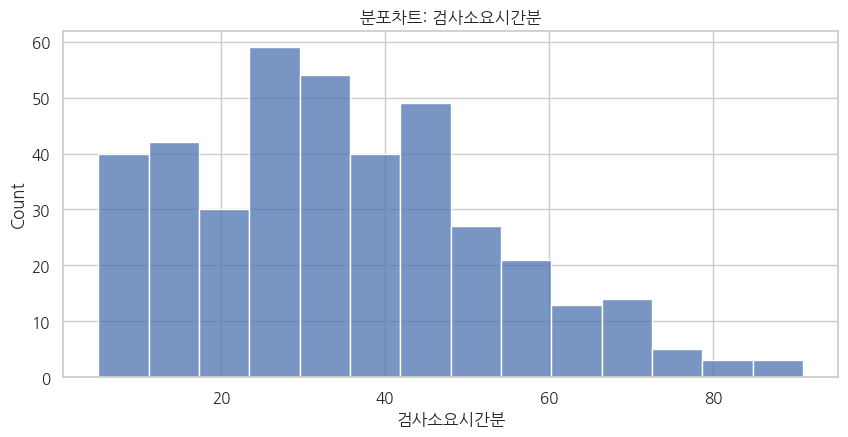

구간별 개수(위 10개 구간):


,개수
검사소요시간분,
"[5.0, 11.143)",40
"[11.143, 17.286)",42
"[17.286, 23.429)",30
"[23.429, 29.571)",59
"[29.571, 35.714)",54
"[35.714, 41.857)",40
"[41.857, 48.0)",49
"[48.0, 54.143)",27
"[54.143, 60.286)",21


In [7]:
X = None                 # 수치형, 예: "단가편차율(%)"  (None = 자동 추천)
Hue = None               # 범주형, 예: "예산과목"  (None = 색 구분 없음)

구간수 = None          # None = 자동(데이터에 맞춰 정함), 정수 = 구간 개수


def 분포차트(X, Hue):
    d = 데이터()
    hue = None if Hue == "(없음)" else Hue
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.histplot(data=d, x=X, hue=hue, bins=구간수 or "auto", multiple="stack", ax=ax)
    ax.set_title(f"분포차트: {X}" + (f" (Hue: {hue})" if hue else ""))
    plt.show()
    edges = np.histogram_bin_edges(d[X].dropna(), bins=구간수 or "auto")
    cut = pd.cut(d[X], edges, include_lowest=True, right=False)
    표 = pd.crosstab(cut, d[hue]) if hue else cut.value_counts(sort=False).to_frame("개수")
    print("구간별 개수(위 10개 구간):")
    display(표.head(10))


분포차트(정하기(X, 추천_수치(1)[0], 수치형(), "X"), 확인(Hue, 범주형(), "Hue") or "(없음)")

## 5. 박스차트 — Y: 수치형, X(Hue): 범주형(선택)
범주마다 q1·median·q3, 울타리(upper/lower fence = q3+1.5·IQR, q1−1.5·IQR), 이상치 개수를 표로 보여 줍니다.

In [8]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("박스차트")

■ 박스차트 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ Y 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → Y = "검사소요시간분"
   추천 순위 (기준: 결측이 적고 값이 다양한 컬럼)
     1. "검사소요시간분"  — 고유값 76개 · 결측 0.0%
     2. "검사항목수"  — 고유값 36개 · 결측 0.0%
     3. "결함발견수"  — 고유값 13개 · 결측 0.0%

▶ X 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → X = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%



[자동 추천] Y = '검사소요시간분'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요
[자동 추천] X = '도면유형'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


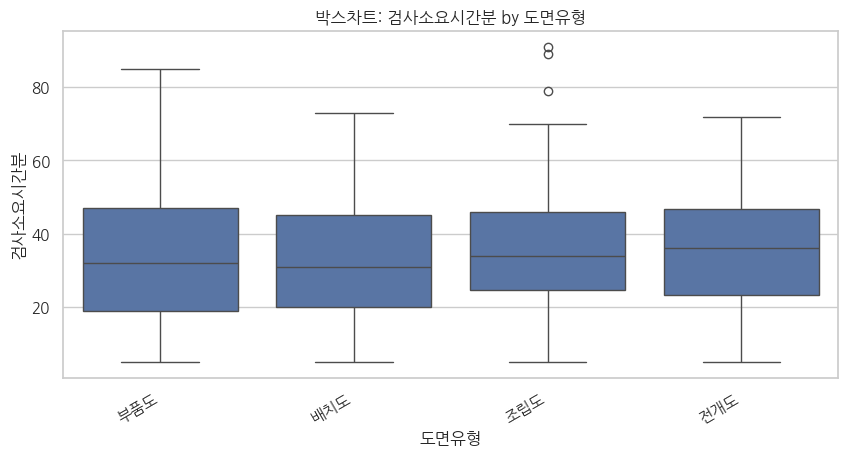

,min,lower fence,q1,median,q3,upper fence,max,IQR,이상치 수,이상치 최솟값(위)
배치도,5.0,5.0,20.00,31.0,45.00,73.0,73.0,25.00,0.0,NaN
부품도,5.0,5.0,19.00,32.0,47.00,85.0,85.0,28.00,0.0,NaN
전개도,5.0,5.0,23.25,36.0,46.75,72.0,72.0,23.50,0.0,NaN
조립도,5.0,5.0,24.75,34.0,46.00,70.0,91.0,21.25,3.0,79.0


In [9]:
Y = None                 # 수치형, 예: "계약단가"  (None = 자동 추천)
X = None                 # 범주형, 예: "지역"  (None = 자동 추천)

울타리_배수 = 1.5


def 박스차트(Y, X):
    d = 데이터()
    x = None if X == "(없음)" else X
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.boxplot(data=d, x=x, y=Y, ax=ax, whis=울타리_배수)
    ax.set_title(f"박스차트: {Y}" + (f" by {x}" if x else ""))
    if x:
        plt.xticks(rotation=30, ha="right")
    plt.show()
    groups = d.groupby(x)[Y] if x else [(Y, d[Y])]
    rows = {}
    for k, s in groups:
        s = s.dropna()
        q1, q2, q3 = s.quantile([.25, .5, .75])
        iqr = q3 - q1
        lo, hi = q1 - 울타리_배수 * iqr, q3 + 울타리_배수 * iqr
        out = s[(s < lo) | (s > hi)]
        rows[k] = {"min": s.min(), "lower fence": max(lo, s[s >= lo].min()), "q1": q1, "median": q2, "q3": q3,
                   "upper fence": min(hi, s[s <= hi].max()), "max": s.max(), "IQR": iqr, "이상치 수": len(out),
                   "이상치 최솟값(위)": s[s > hi].min() if (s > hi).any() else None}
    display(pd.DataFrame(rows).T.round(3))


박스차트(정하기(Y, 추천_수치(1)[0], 수치형(), "Y"), 정하기(X, 추천_범주(), 범주형(), "X") or "(없음)")

## 6. 산점도 — X·Y: 수치형, Hue: 범주형(선택)

In [10]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("산점도")

■ 산점도 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ X 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → X = "검사소요시간분"
   추천 순위 (기준: 상관관계가 높은 컬럼 쌍 위주)
     1. "검사소요시간분"  — '결함발견수' 와 상관 0.44
     2. "결함발견수"  — '검사소요시간분' 와 상관 0.44
     3. "검사항목수"  — '검사소요시간분' 와 상관 0.03

▶ Y 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → Y = "검사소요시간분"
   추천 순위 (기준: 상관관계가 높은 컬럼 쌍 위주)
     1. "검사소요시간분"  — '결함발견수' 와 상관 0.44
     2. "결함발견수"  — '검사소요시간분' 와 상관 0.44
     3. "검사항목수"  — '검사소요시간분' 와 상관 0.03

▶ Hue 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → Hue = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%



[자동 추천] X = '검사소요시간분'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요
[자동 추천] Y = '검사항목수'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


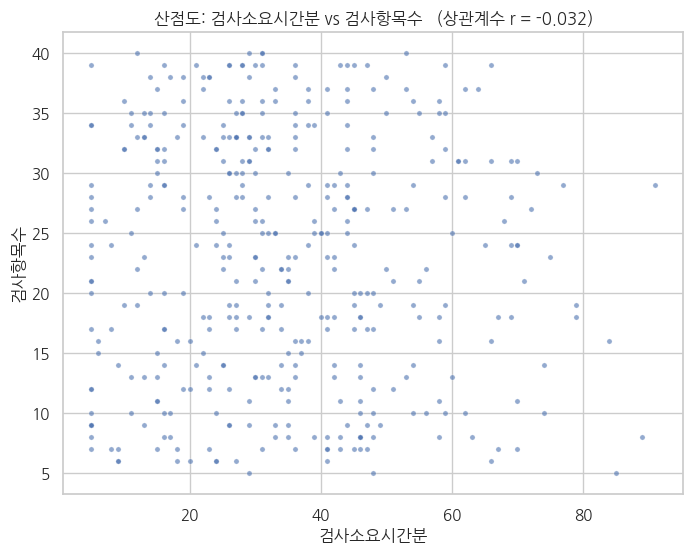

In [11]:
X = None                 # 수치형, 예: "계약단가"
Y = None                 # 수치형, 예: "기준단가"  (None = 자동 추천)
Hue = None               # 범주형(None = 색 구분 없음)

최대점수 = 5000        # 점이 너무 많으면 이 수만큼만 무작위로 뽑아 그린다


def 산점도(X, Y, Hue):
    d = 데이터()
    d = d.sample(min(len(d), 최대점수), random_state=난수_시드)
    hue = None if Hue == "(없음)" else Hue
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(data=d, x=X, y=Y, hue=hue, s=14, alpha=.6, ax=ax)
    ax.set_title(f"산점도: {X} vs {Y}   (상관계수 r = {데이터()[[X, Y]].corr().iloc[0, 1]:.3f})")
    plt.show()


_x, _y = (추천_수치(2) + [None, None])[:2]
if len(수치형()) < 2 and (X is None or Y is None):
    print("산점도에는 수치형 컬럼이 2개 이상 필요합니다 — 이 데이터의 수치형:", 수치형())
else:
    산점도(정하기(X, _x, 수치형(), "X"), 정하기(Y, _y, 수치형(), "Y"), 확인(Hue, 범주형(), "Hue") or "(없음)")

## 7. 히트맵 (상관관계) — 수치형 컬럼 여러 개

In [12]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("히트맵")

■ 히트맵 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼들 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → 컬럼들 = ["검사소요시간분", "결함발견수", "검사항목수"]
   추천 순위 (기준: 상관관계가 높은 컬럼 쌍 위주)
     1. "검사소요시간분"  — '결함발견수' 와 상관 0.44
     2. "결함발견수"  — '검사소요시간분' 와 상관 0.44
     3. "검사항목수"  — '검사소요시간분' 와 상관 0.03



[자동 추천] 컬럼들 = ['검사소요시간분', '검사항목수', '결함발견수']   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


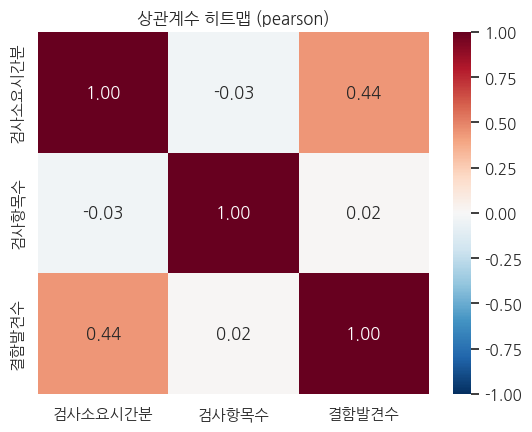

상관이 큰 순서(절댓값):


상관계수
검사소요시간분 결함발견수    0.440
        검사항목수   -0.032
검사항목수   결함발견수    0.015
검사소요시간분 검사소요시간분    NaN
검사항목수   검사소요시간분    NaN
        검사항목수      NaN
결함발견수   검사소요시간분    NaN
        검사항목수      NaN

In [13]:
컬럼들 = None            # 수치형 여러 개, 예: ["수량", "계약단가", "계약금액", "집행률(%)"]  (None = 자동 추천 6개)

상관_방법 = "pearson"       # "pearson" | "spearman" | "kendall"


def 히트맵(컬럼들):
    if len(컬럼들) < 2:
        print("컬럼을 2개 이상 고르세요")
        return
    c = 데이터()[list(컬럼들)].corr(method=상관_방법)
    fig, ax = plt.subplots(figsize=(1.1 * len(c) + 3, 0.9 * len(c) + 2))
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"상관계수 히트맵 ({상관_방법})")
    plt.show()
    pairs = c.where(np.triu(np.ones(c.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
    print("상관이 큰 순서(절댓값):")
    display(pairs.head(8).round(3).to_frame("상관계수"))


히트맵(정하기(컬럼들, 추천_수치(6), 수치형(), "컬럼들"))

## 8. 막대차트 (범주별 개수·평균) — X: 범주형, Y: 수치형(선택, 고르면 평균)

In [14]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("막대차트")

■ 막대차트 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ X 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → X = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%

▶ Y 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → Y = "검사소요시간분"
   추천 순위 (기준: 결측이 적고 값이 다양한 컬럼)
     1. "검사소요시간분"  — 고유값 76개 · 결측 0.0%
     2. "검사항목수"  — 고유값 36개 · 결측 0.0%
     3. "결함발견수"  — 고유값 13개 · 결측 0.0%



[자동 추천] X = '도면유형'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


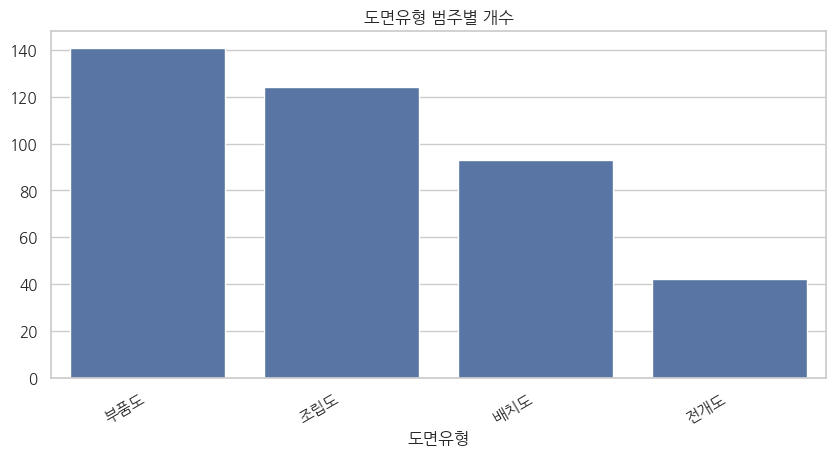

도면유형,부품도,조립도,배치도,전개도
값,141,124,93,42


In [15]:
X = None                 # 범주형, 예: "예산과목"  (None = 자동 추천)
Y = None                 # 수치형(쓰면 범주별 평균, None = 개수)

def 막대차트(X, Y):
    d = 데이터()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    if Y == "(없음)":
        s = d[X].value_counts()
        ax.set_title(f"{X} 범주별 개수")
    else:
        s = d.groupby(X)[Y].mean().sort_values(ascending=False)
        ax.set_title(f"{X} 범주별 {Y} 평균")
    sns.barplot(x=s.index.astype(str), y=s.values, ax=ax)
    plt.xticks(rotation=30, ha="right")
    plt.show()
    display(s.round(3).to_frame("값").T)


막대차트(정하기(X, 추천_범주(), 범주형(), "X"), 확인(Y, 수치형(), "Y") or "(없음)")

## 9. 라인차트 (시계열) — 날짜 컬럼, Y: 수치형, Hue: 범주형(선택)

In [16]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("라인차트")

■ 라인차트 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 날짜 에 쓸 수 있는 날짜형 컬럼 1개:
   "검사일자"
   바로 붙여 넣기 → 날짜 = "검사일자"
   추천 순위 (기준: 날짜로 읽히는 컬럼(기간))
     1. "검사일자"  — 2024-01-01 ~ 2025-12-27

▶ Y 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → Y = "검사소요시간분"
   추천 순위 (기준: 결측이 적고 값이 다양한 컬럼)
     1. "검사소요시간분"  — 고유값 76개 · 결측 0.0%
     2. "검사항목수"  — 고유값 36개 · 결측 0.0%
     3. "결함발견수"  — 고유값 13개 · 결측 0.0%

▶ Hue 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → Hue = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%



[자동 추천] 날짜 = '검사일자'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요
[자동 추천] Y = '검사소요시간분'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


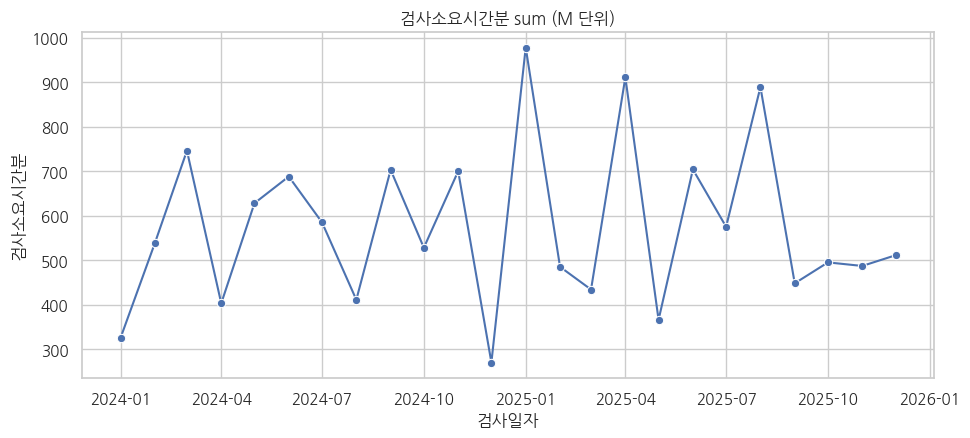

In [17]:
날짜 = None              # 날짜형, 예: "계약일자"  (None = 자동 추천)
Y = None                 # 수치형, 예: "집행액"  (None = 자동 추천)
Hue = None               # 범주형(범주 10개 이하 권장, None = 구분 없음)

집계_단위 = "M"        # "D" 일, "W" 주, "M" 월, "Q" 분기
집계_방법 = "sum"      # "sum" | "mean" | "count"


def 라인차트(날짜, Y, Hue):
    d = 데이터().copy()
    d[날짜] = 날짜로(d[날짜])
    hue = None if Hue == "(없음)" else Hue
    freq = {"M": "MS", "Q": "QS"}.get(집계_단위, 집계_단위)
    keys = [pd.Grouper(key=날짜, freq=freq)] + ([hue] if hue else [])
    g = d.groupby(keys)[Y].agg(집계_방법).reset_index()
    fig, ax = plt.subplots(figsize=(11, 4.5))
    sns.lineplot(data=g, x=날짜, y=Y, hue=hue, marker="o", ax=ax)
    ax.set_title(f"{Y} {집계_방법} ({집계_단위} 단위)")
    plt.show()


if 날짜형():
    라인차트(정하기(날짜, 추천_날짜(), 날짜형(), "날짜"), 정하기(Y, 추천_수치(1)[0], 수치형(), "Y"), 확인(Hue, 범주형(), "Hue") or "(없음)")
else:
    print("날짜 컬럼이 없습니다")

## 10. 워드클라우드 — 문자열 컬럼(범주·문장)
`wordcloud` 패키지가 없으면 상위 단어 빈도 막대그래프로 대신 보여 줍니다.

In [18]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("워드클라우드")

■ 워드클라우드 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼 에 쓸 수 있는 문자열 컬럼 7개:
   "검사번호", "검사일자", "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → 컬럼 = "결함사유"
   추천 순위 (기준: 글이 긴(문장) 컬럼)
     1. "결함사유"  — 평균 9글자 · 고유값 6개
     2. "검사번호"  — 평균 8글자 · 고유값 400개
     3. "업체유형"  — 평균 4글자 · 고유값 3개
     4. "도면유형"  — 평균 3글자 · 고유값 4개
     5. "합격여부"  — 평균 1글자 · 고유값 2개



[자동 추천] 컬럼 = '결함사유'   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요
워드클라우드 대신 빈도 막대그래프( OSError )


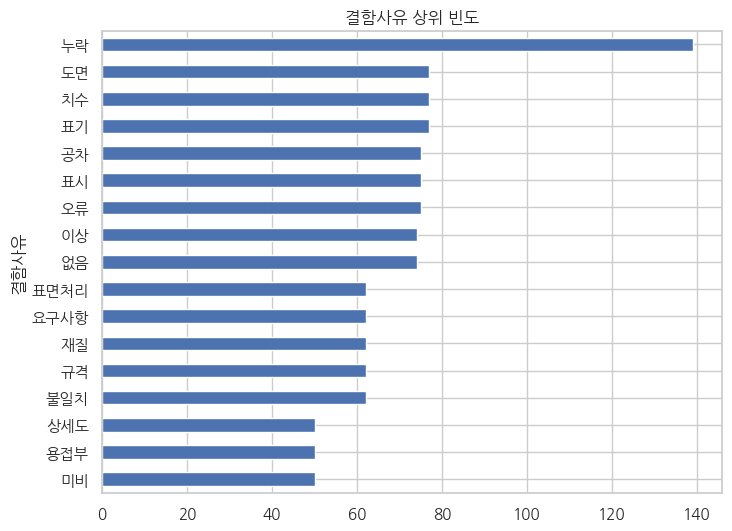

결함사유,누락,도면,치수,표기,공차,표시,오류,이상,없음,표면처리
빈도,139,77,77,77,75,75,75,74,74,62


In [19]:
컬럼 = None              # 문자열(범주·문장), 예: "부대피드백"  (None = 가장 긴 글 컬럼)

최대단어수 = 80
글꼴경로 = {"Windows": "C:/Windows/Fonts/malgun.ttf", "Darwin": "/System/Library/Fonts/AppleSDGothicNeo.ttc"}.get(platform.system(),
                                                                                                         "/usr/share/fonts/truetype/nanum/NanumGothic.ttf")


def 워드클라우드(컬럼):
    s = 데이터()[컬럼].dropna().astype(str)
    # 문장 컬럼이면 낱말(한글·영문·숫자 2글자 이상)로 나눠 세고, 짧은 범주 컬럼이면 값 그대로 센다
    words = s.str.findall(r"[가-힣A-Za-z0-9]{2,}").explode() if s.str.contains(" ").mean() > .3 else s
    freq = words.value_counts().head(최대단어수)
    try:
        from wordcloud import WordCloud
        wc = WordCloud(font_path=글꼴경로, width=900, height=420, background_color="white").generate_from_frequencies(freq.to_dict())
        plt.figure(figsize=(11, 5)); plt.imshow(wc); plt.axis("off"); plt.title(f"워드클라우드: {컬럼}"); plt.show()
    except Exception as e:
        print("워드클라우드 대신 빈도 막대그래프(", type(e).__name__, ")")
        freq.head(20).sort_values().plot.barh(figsize=(8, 6), title=f"{컬럼} 상위 빈도"); plt.show()
    display(freq.head(10).to_frame("빈도").T)


워드클라우드(정하기(컬럼, 추천_글자(), [c for c in df.columns if 글자(c)], "컬럼"))

---
# 비지도학습 분석
`컬럼들` 에 수치형 컬럼을 여러 개 쓰면 결측 행을 빼고 **표준화(StandardScaler)** 한 뒤 분석합니다.

In [20]:
from sklearn.preprocessing import StandardScaler


def 분석행렬(컬럼들):
    """선택 컬럼(수치형)의 결측 행을 빼고 표준화한 행렬과 원래 데이터."""
    d = 데이터()[list(컬럼들)].dropna()
    return StandardScaler().fit_transform(d), d

## 11. PCA (주성분 분석) — 수치형 여러 개, 색 구분: 범주형(선택)

In [21]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("PCA")

■ PCA — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼들 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → 컬럼들 = ["검사소요시간분", "검사항목수"]
   추천 순위 (기준: 값의 분포가 다양하고 서로 중복되지 않는 컬럼)
     1. "검사소요시간분"  — 변동계수 0.53 · 다른 후보와 상관 0.95 미만
     2. "검사항목수"  — 변동계수 0.45 · 다른 후보와 상관 0.95 미만

▶ 색구분 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → 색구분 = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%



[자동 추천] 컬럼들 = ['검사소요시간분', '검사항목수', '결함발견수']   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요
설명 분산 비율: [0.48   0.3341]  누적: 0.8141


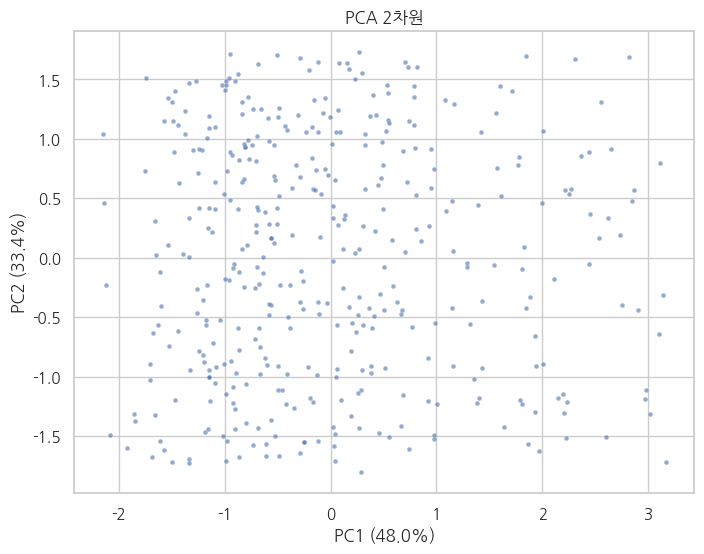

,PC1,PC2
검사소요시간분,0.708000,-0.034000
검사항목수,-0.027000,0.997000
결함발견수,0.706000,0.072000


In [22]:
컬럼들 = None            # 수치형 여러 개, 예: ["수량", "계약단가", "집행률(%)"]  (None = 자동 추천 5개)
색구분 = None            # 범주형(None = 색 구분 없음)

주성분_수 = 2


def PCA_분석(컬럼들, 색구분):
    from sklearn.decomposition import PCA
    if len(컬럼들) < 2:
        print("컬럼을 2개 이상 고르세요"); return
    Xs, d = 분석행렬(컬럼들)
    pca = PCA(n_components=min(주성분_수, len(컬럼들)), random_state=난수_시드)
    Z = pca.fit_transform(Xs)
    ratio = pca.explained_variance_ratio_
    print("설명 분산 비율:", np.round(ratio, 4), " 누적:", round(float(ratio.sum()), 4))
    hue = None if 색구분 == "(없음)" else 데이터().loc[d.index, 색구분].astype(str)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1] if Z.shape[1] > 1 else np.zeros(len(Z)), hue=hue, s=12, alpha=.6, ax=ax)
    ax.set(xlabel=f"PC1 ({ratio[0]:.1%})", ylabel=f"PC2 ({ratio[1]:.1%})" if len(ratio) > 1 else "", title="PCA 2차원")
    plt.show()
    try:
        display(pd.DataFrame(pca.components_.T, index=컬럼들, columns=[f"PC{i + 1}" for i in range(len(ratio))]).round(3).style.set_caption("적재값(loadings)"))
    except Exception:
        display(pd.DataFrame(pca.components_.T, index=컬럼들, columns=[f"PC{i + 1}" for i in range(len(ratio))]).round(3))


try:
    import piplite
    await piplite.install("jinja2")  # pandas .style 에 필요(없으면 색칠 없이 표만 출력) — 함수 호출 전, 셀 맨 위 수준에서 설치
except Exception:
    pass
PCA_분석(정하기(컬럼들, 추천_수치(5), 수치형(), "컬럼들"), 확인(색구분, 범주형(), "색구분") or "(없음)")

## 12. t-SNE — 수치형 여러 개, 색 구분: 범주형(선택)

In [23]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("t-SNE")

■ t-SNE — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼들 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → 컬럼들 = ["검사소요시간분", "검사항목수"]
   추천 순위 (기준: 값의 분포가 다양하고 서로 중복되지 않는 컬럼)
     1. "검사소요시간분"  — 변동계수 0.53 · 다른 후보와 상관 0.95 미만
     2. "검사항목수"  — 변동계수 0.45 · 다른 후보와 상관 0.95 미만

▶ 색구분 에 쓸 수 있는 범주형 컬럼 5개:
   "도면유형", "업체유형", "합격여부", "재검사여부", "결함사유"
   바로 붙여 넣기 → 색구분 = "도면유형"
   추천 순위 (기준: 고유 범주가 2~8개이며 결측치가 적은 컬럼)
     1. "도면유형"  — 범주 4개 · 결측 0.0%
     2. "업체유형"  — 범주 3개 · 결측 0.0%
     3. "합격여부"  — 범주 2개 · 결측 0.0%
     4. "재검사여부"  — 범주 2개 · 결측 0.0%
     5. "결함사유"  — 범주 6개 · 결측 0.0%



[자동 추천] 컬럼들 = ['검사소요시간분', '검사항목수', '결함발견수']   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


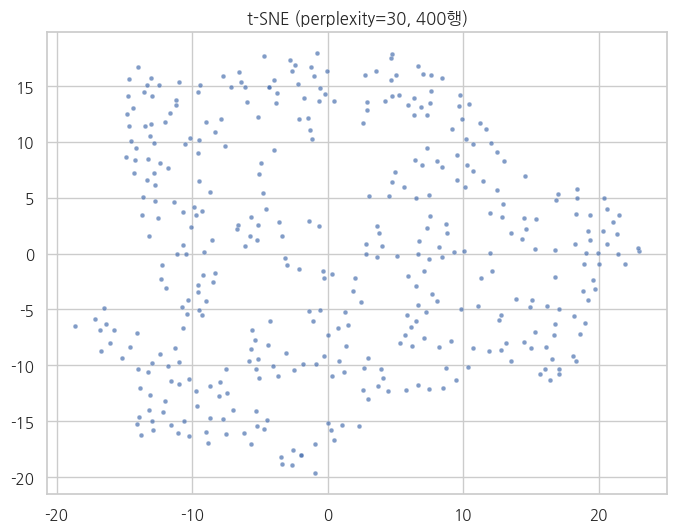

In [24]:
컬럼들 = None            # 수치형 여러 개, 예: ["수량", "계약단가", "집행률(%)"]  (None = 자동 추천 5개)
색구분 = None            # 범주형(None = 색 구분 없음)

perplexity = 30          # 보통 5~50, 데이터 수보다 작아야 함
t_SNE_최대행수 = 3000     # t-SNE 는 느리므로 이 수만큼만 무작위로 뽑아 계산


def tSNE_분석(컬럼들, 색구분):
    from sklearn.manifold import TSNE
    if len(컬럼들) < 2:
        print("컬럼을 2개 이상 고르세요"); return
    Xs, d = 분석행렬(컬럼들)
    if len(d) > t_SNE_최대행수:
        idx = np.random.default_rng(난수_시드).choice(len(d), t_SNE_최대행수, replace=False)
        Xs, d = Xs[idx], d.iloc[idx]
    Z = TSNE(n_components=2, perplexity=min(perplexity, len(d) - 1), random_state=난수_시드, init="pca").fit_transform(Xs)
    hue = None if 색구분 == "(없음)" else 데이터().loc[d.index, 색구분].astype(str)
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=hue, s=12, alpha=.7, ax=ax)
    ax.set_title(f"t-SNE (perplexity={perplexity}, {len(d):,}행)")
    plt.show()


tSNE_분석(정하기(컬럼들, 추천_수치(5), 수치형(), "컬럼들"), 확인(색구분, 범주형(), "색구분") or "(없음)")

## 13. K-Means 군집분석 — 수치형 여러 개
엘보우(inertia)·실루엣 점수로 군집 수를 고르는 근거를 함께 보여 주고, 군집별 평균을 표로 냅니다.
결과는 전역 변수 `군집결과` 에 저장되어 아래 저장 셀로 CSV 를 내려받을 수 있습니다.

In [25]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("군집분석")

■ 군집분석 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼들 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → 컬럼들 = ["검사소요시간분", "검사항목수"]
   추천 순위 (기준: 값의 분포가 다양하고 서로 중복되지 않는 컬럼)
     1. "검사소요시간분"  — 변동계수 0.53 · 다른 후보와 상관 0.95 미만
     2. "검사항목수"  — 변동계수 0.45 · 다른 후보와 상관 0.95 미만



[자동 추천] 컬럼들 = ['검사소요시간분', '검사항목수', '결함발견수']   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


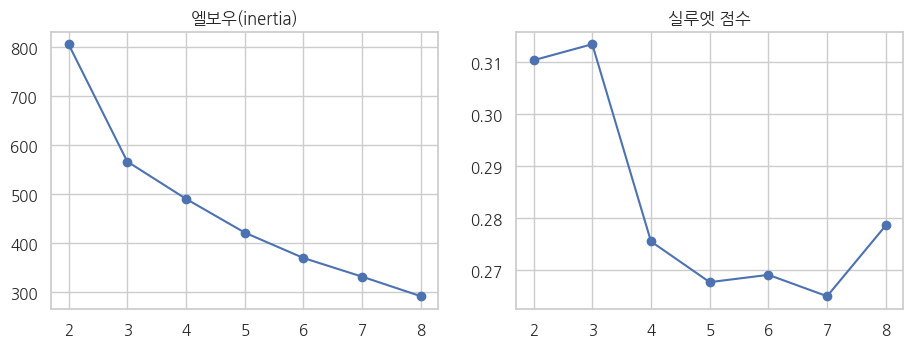

군집 수 3: 군집별 행 수 [159, 147, 94]


,검사소요시간분,검사항목수,결함발견수
군집,,,
0,27.818,32.157,3.396
1,26.946,13.891,2.585
2,57.702,21.106,7.702


In [26]:
컬럼들 = None            # 수치형 여러 개, 예: ["수량", "계약단가", "집행률(%)"]  (None = 자동 추천 4개)

군집_수 = 3
후보_군집수 = range(2, 9)
실루엣_최대행수 = 3000


def KMeans_분석(컬럼들):
    global 군집결과
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    if len(컬럼들) < 2:
        print("컬럼을 2개 이상 고르세요"); return
    Xs, d = 분석행렬(컬럼들)
    rs = np.random.default_rng(난수_시드)
    sub = rs.choice(len(Xs), min(len(Xs), 실루엣_최대행수), replace=False)
    inert, sil = [], []
    for k in 후보_군집수:
        km = KMeans(n_clusters=k, n_init=10, random_state=난수_시드).fit(Xs)
        inert.append(km.inertia_)
        sil.append(silhouette_score(Xs[sub], km.labels_[sub]))
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    axs[0].plot(list(후보_군집수), inert, "o-"); axs[0].set_title("엘보우(inertia)")
    axs[1].plot(list(후보_군집수), sil, "o-"); axs[1].set_title("실루엣 점수")
    plt.show()
    km = KMeans(n_clusters=군집_수, n_init=10, random_state=난수_시드).fit(Xs)
    군집결과 = 데이터().loc[d.index].assign(군집=km.labels_)
    print(f"군집 수 {군집_수}: 군집별 행 수 {np.bincount(km.labels_).tolist()}")
    display(군집결과.groupby("군집")[list(컬럼들)].mean().round(3))


KMeans_분석(정하기(컬럼들, 추천_수치(4), 수치형(), "컬럼들"))

## 14. 계층적 군집분석 (덴드로그램) — 수치형 여러 개

In [27]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("군집분석")

■ 군집분석 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼들 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → 컬럼들 = ["검사소요시간분", "검사항목수"]
   추천 순위 (기준: 값의 분포가 다양하고 서로 중복되지 않는 컬럼)
     1. "검사소요시간분"  — 변동계수 0.53 · 다른 후보와 상관 0.95 미만
     2. "검사항목수"  — 변동계수 0.45 · 다른 후보와 상관 0.95 미만



[자동 추천] 컬럼들 = ['검사소요시간분', '검사항목수', '결함발견수']   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


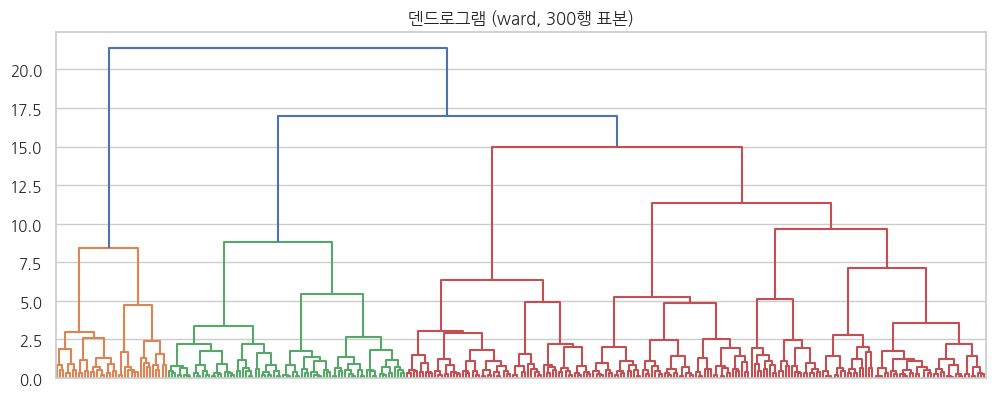

In [28]:
컬럼들 = None            # 수치형 여러 개, 예: ["수량", "계약단가", "집행률(%)"]  (None = 자동 추천 4개)

연결_방법 = "ward"        # "ward" | "complete" | "average" | "single"
덴드로그램_최대행수 = 300


def 계층군집_분석(컬럼들):
    from scipy.cluster.hierarchy import dendrogram, linkage
    if len(컬럼들) < 2:
        print("컬럼을 2개 이상 고르세요"); return
    Xs, d = 분석행렬(컬럼들)
    idx = np.random.default_rng(난수_시드).choice(len(Xs), min(len(Xs), 덴드로그램_최대행수), replace=False)
    Z = linkage(Xs[idx], method=연결_방법)
    plt.figure(figsize=(12, 4.5))
    dendrogram(Z, no_labels=True, color_threshold=0.7 * Z[:, 2].max())
    plt.title(f"덴드로그램 ({연결_방법}, {len(idx)}행 표본)")
    plt.show()


계층군집_분석(정하기(컬럼들, 추천_수치(4), 수치형(), "컬럼들"))

## 15. DBSCAN — 수치형 여러 개 (군집 수를 정하지 않고 밀도로 묶음, -1 은 잡음)

In [29]:
# 이 차트에 쓸 수 있는 컬럼(복사용)과 추천 순위 — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
컬럼_안내("군집분석")

■ 군집분석 — 아래 셀 맨 위 변수에 복사해 쓰세요

▶ 컬럼들 에 쓸 수 있는 수치형 컬럼 3개:
   "검사항목수", "검사소요시간분", "결함발견수"
   바로 붙여 넣기 → 컬럼들 = ["검사소요시간분", "검사항목수"]
   추천 순위 (기준: 값의 분포가 다양하고 서로 중복되지 않는 컬럼)
     1. "검사소요시간분"  — 변동계수 0.53 · 다른 후보와 상관 0.95 미만
     2. "검사항목수"  — 변동계수 0.45 · 다른 후보와 상관 0.95 미만



[자동 추천] 컬럼들 = ['검사소요시간분', '검사항목수', '결함발견수']   ← 바꾸려면 셀 맨 위 변수에 컬럼명을 쓰세요


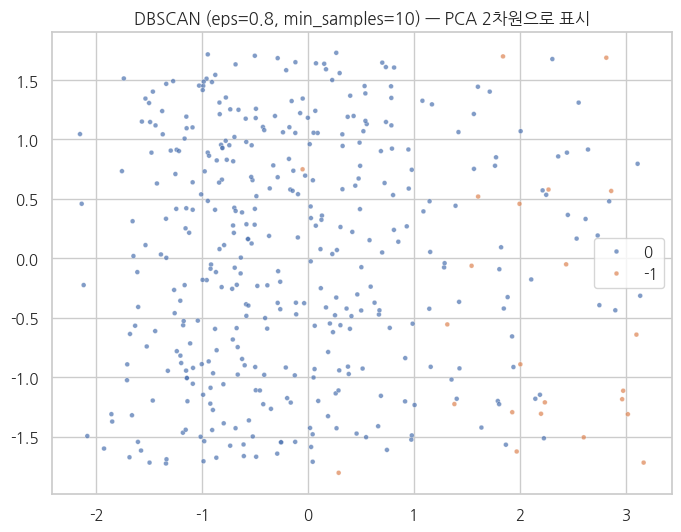

군집별 행 수(-1 = 잡음): {-1: 23, 0: 377}


In [30]:
컬럼들 = None            # 수치형 여러 개, 예: ["수량", "계약단가", "집행률(%)"]  (None = 자동 추천 4개)

eps = 0.8
min_samples = 10
DBSCAN_최대행수 = 5000


def DBSCAN_분석(컬럼들):
    from sklearn.cluster import DBSCAN
    from sklearn.decomposition import PCA
    if len(컬럼들) < 2:
        print("컬럼을 2개 이상 고르세요"); return
    Xs, d = 분석행렬(컬럼들)
    idx = np.random.default_rng(난수_시드).choice(len(Xs), min(len(Xs), DBSCAN_최대행수), replace=False)
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xs[idx])
    Z = PCA(n_components=2, random_state=난수_시드).fit_transform(Xs[idx])
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=lab.astype(str), s=12, alpha=.7, ax=ax)
    ax.set_title(f"DBSCAN (eps={eps}, min_samples={min_samples}) — PCA 2차원으로 표시")
    plt.show()
    print("군집별 행 수(-1 = 잡음):", pd.Series(lab).value_counts().sort_index().to_dict())


DBSCAN_분석(정하기(컬럼들, 추천_수치(4), 수치형(), "컬럼들"))

## 16. 군집 결과 저장 (13번 K-Means 결과)

In [31]:
저장_파일 = "군집결과.csv"
if "군집결과" in globals():
    군집결과.to_csv(저장_파일, index=False, encoding="utf-8-sig")
    print(f"'{저장_파일}' 저장: {len(군집결과):,}행 (군집 컬럼 포함)")
else:
    print("13번 K-Means 셀을 먼저 실행하세요")

'군집결과.csv' 저장: 400행 (군집 컬럼 포함)


# AIDU 머신러닝 · 딥러닝 · 변수 영향도 — 주피터 노트북 실습 (3팀 · AI기반 도면판독·품질검사 합성데이터, 실제 부대명과 무관)

데이터로 **머신러닝 모델 비교**, **딥러닝 학습**, **변수 영향도**, **시뮬레이션(예측)** 을 파이썬 코드로 해 봅니다.

**사용 순서**
1. `0. 준비` → `1. 데이터 불러오기`(`파일_경로` 에 CSV·XLSX 경로).
2. `2. 공통 설정` 셀이 모든 컬럼 이름과 유형을 보여 줍니다.
3. `3. 종속·입력 컬럼` 안내 셀이 **종속변수 추천 순위**, **입력 컬럼 추천**, **빼는 컬럼과 이유**를 보여 줍니다.
   바로 아래 셀의 `종속`, `입력`, `제외` 변수에 컬럼 이름을 직접 쓰면 바뀝니다(`None` = 자동 추천).
4. 4~7번 셀을 차례로 실행합니다(머신러닝 → 딥러닝 → 변수 영향도 → 시뮬레이션).
   - 이름을 잘못 쓰면 비슷한 이름을 알려 줍니다(예: "혹시 '하자여부'?").
   - 그 밖의 설정(모델 종류, 은닉층, epoch 등)은 각 셀 맨 위 변수로 바꿉니다.

## 0. 준비

In [32]:
# 필요하면 먼저 설치하세요(한 번만): %pip install openpyxl seaborn scikit-learn tensorflow
import io, platform, warnings, difflib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
try:
    import piplite
    await piplite.install("seaborn")        # Pyodide 기본 배포판에는 없어 로컬 미러에서 설치
    await piplite.install("koreanize-matplotlib")
except ImportError:
    pass
import seaborn as sns
try:
    # koreanize-matplotlib 0.1.1 은 distutils 를 써서 파이썬 3.12+ 에서 import 가 깨진다 — 번들 폰트 파일만 직접 등록
    import glob, site, matplotlib.font_manager as fm
    _cands = []
    for _sp in (site.getsitepackages() if hasattr(site, "getsitepackages") else []):
        _cands += glob.glob(_sp + "/koreanize_matplotlib/fonts/NanumGothic.ttf")
    _cands += glob.glob("/lib/python*/site-packages/koreanize_matplotlib/fonts/NanumGothic.ttf")
    if not _cands:
        raise FileNotFoundError("NanumGothic.ttf")
    fm.fontManager.addfont(_cands[0])
    plt.rc("font", family=fm.FontProperties(fname=_cands[0]).get_name())  # 한글 글꼴 자동 설정(번들 NanumGothic, 오프라인 가능)
except Exception:
    plt.rc("font", family={"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}.get(platform.system(), "NanumGothic"))
plt.rc("axes", unicode_minus=False)
sns.set_theme(style="whitegrid", font=plt.rcParams["font.family"][0])

def 날짜로(s):
    """문자열 → 날짜. pandas 2 는 format="mixed", 그보다 옛 판은 자동 판별로 읽는다."""
    try:
        return pd.to_datetime(s, errors="coerce", format="mixed")
    except (TypeError, ValueError):
        return pd.to_datetime(s, errors="coerce")


try:                                   # 딥러닝: tensorflow 가 없으면 scikit-learn 신경망(MLP)으로 대신한다
    import tensorflow as tf
    tf.get_logger().setLevel("ERROR")
    딥러닝_도구 = "tensorflow"
except ImportError:
    tf = None
    딥러닝_도구 = "scikit-learn MLP"
print("준비 완료 — 딥러닝:", 딥러닝_도구)

준비 완료 — 딥러닝: scikit-learn MLP


## 1. 데이터 불러오기
`파일_경로` 에 분석할 CSV 또는 XLSX 파일 경로를 적고 실행하세요(노트북과 같은 폴더 기준). 한글 CSV 는 utf-8 / cp949 를 자동으로 판별합니다.

In [33]:
파일_경로 = "../../data/3팀_품질검사데이터.csv"     # ← 분석할 파일 경로(노트북 기준)


from pathlib import Path

def 파일_읽기(이름):
    if 이름.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(이름)
    for enc in ("utf-8-sig", "cp949"):
        try:
            return pd.read_csv(이름, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("CSV 인코딩을 알 수 없습니다(utf-8, cp949 아님)")



def 파일_경로_찾기(이름):
    """JupyterLite의 현재 폴더 차이와 관계없이 files/data의 예시 CSV를 찾는다."""
    경로 = Path(이름)
    if 경로.exists():
        return str(경로)
    for 기준 in (Path("data"), Path("../data"), Path("../../data"), Path("/drive/data")):
        후보 = 기준 / 경로.name
        if 후보.exists():
            return str(후보)
    return 이름

df = 파일_읽기(파일_경로_찾기(파일_경로))
print(f"'{파일_경로}' 를 읽었습니다: {df.shape[0]:,}행 × {df.shape[1]}열")
display(df.head())

'../../data/3팀_품질검사데이터.csv' 를 읽었습니다: 400행 × 10열


,검사번호,검사일자,도면유형,업체유형,검사항목수,검사소요시간분,결함발견수,합격여부,재검사여부,결함사유
0,QC-00001,2024-01-26,부품도,특수계약업체,39,45,6,부,부,이상 없음
1,QC-00002,2025-08-14,부품도,중소기업,32,15,4,여,부,표면처리 요구사항 누락
2,QC-00003,2025-06-26,배치도,특수계약업체,12,35,2,여,여,이상 없음
3,QC-00004,2025-11-08,조립도,중소기업,6,27,1,여,부,이상 없음
4,QC-00005,2025-03-07,배치도,일반업체,30,26,1,여,여,공차 표시 오류


## 2. 공통 설정 — 컬럼 목록 · 데이터 범위
모든 컬럼의 이름·유형·고유값 수·결측 수·예시값을 표로 보여 줍니다. 아래 셀에서는 이 표의 컬럼명을 그대로 복사해 씁니다.

`데이터_범위` 는 앞에서부터 몇 행을 분석에 쓸지(`None` = 전체), `학습_최대행수` 는 학습 속도를 위해 무작위로 뽑아 쓸 최대 행 수입니다.

In [34]:
데이터_범위 = None          # None = 전체, 정수 = 앞에서부터 그 행 수만 사용
학습_최대행수 = 20000       # 행이 많으면 이 수만큼 무작위로 뽑아 학습(None = 모두)
난수_시드 = 42


def 데이터():
    d = df if 데이터_범위 is None else df.iloc[:int(데이터_범위)]
    if 학습_최대행수 and len(d) > 학습_최대행수:
        d = d.sample(학습_최대행수, random_state=난수_시드)
    return d


def 글자(c):
    return pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object


def 수치형():
    return [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]


def 범주형(최대범주=30):
    return [c for c in df.columns if (글자(c) and df[c].nunique() <= 최대범주) or (pd.api.types.is_numeric_dtype(df[c]) and df[c].nunique() <= 10)]


def 날짜형():
    out = []
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            out.append(c)
        elif 글자(c):
            s = 날짜로(df[c].dropna().head(50))
            if len(s) and s.notna().mean() > 0.9:
                out.append(c)
    return out


def 유형(c):
    if c in 날짜형():
        return "날짜형"
    if pd.api.types.is_numeric_dtype(df[c]):
        return "수치형" + ("(범주처럼 쓸 수 있음)" if df[c].nunique() <= 10 else "")
    return "범주형" if df[c].nunique() <= 30 else "글자형"


def 컬럼_보기():
    rows = [{"컬럼명": c, "유형": 유형(c), "고유값 수": df[c].nunique(), "결측 수": int(df[c].isna().sum()),
             "예시값": ", ".join(map(str, df[c].dropna().unique()[:3]))} for c in df.columns]
    with pd.option_context("display.max_rows", 300, "display.max_colwidth", 60):
        display(pd.DataFrame(rows))


class 컬럼이름오류(ValueError):
    """주피터에서 긴 오류 추적 없이 안내 한 줄만 보여 준다."""
    def _render_traceback_(self):
        return [f"⚠ {self}"]


def 확인(값, 허용=None, 이름="컬럼"):
    """None 이면 None, 문자열이면 컬럼 하나, 리스트면 여러 컬럼을 확인한다. 없는 이름이면 비슷한 이름을 알려 준다."""
    if 값 is None:
        return None
    if isinstance(값, (list, tuple)):
        return [확인(v, 허용, 이름) for v in 값]
    if 값 not in df.columns:
        후보 = difflib.get_close_matches(str(값), [str(c) for c in df.columns], n=3, cutoff=0.4) or [c for c in df.columns if str(값) in str(c)][:3]
        raise 컬럼이름오류(f"{이름} '{값}' 은(는) 데이터에 없습니다." + (f" 혹시 {' / '.join(repr(x) for x in 후보)} ?" if 후보 else " 2번 셀의 컬럼 목록을 확인하세요."))
    if 허용 is not None and 값 not in 허용:
        raise 컬럼이름오류(f"{이름} '{값}' 은(는) 여기에 쓸 수 없습니다(유형: {유형(값)}).")
    return 값


def 따옴표(cols):
    return ", ".join(f'"{c}"' for c in cols)


print(f"사용 데이터: {len(데이터()):,}행 / 전체 {len(df):,}행")
컬럼_보기()

사용 데이터: 400행 / 전체 400행


,컬럼명,유형,고유값 수,결측 수,예시값
0,검사번호,글자형,400,0,"QC-00001, QC-00002, QC-00003"
1,검사일자,날짜형,299,0,"2024-01-26, 2025-08-14, 2025-06-26"
2,도면유형,범주형,4,0,"부품도, 배치도, 조립도"
3,업체유형,범주형,3,0,"특수계약업체, 중소기업, 일반업체"
4,검사항목수,수치형,36,0,"39, 32, 12"
5,검사소요시간분,수치형,76,0,"45, 15, 35"
6,결함발견수,수치형,13,0,"6, 4, 2"
7,합격여부,범주형,2,0,"부, 여"
8,재검사여부,범주형,2,0,"부, 여"
9,결함사유,범주형,6,0,"이상 없음, 표면처리 요구사항 누락, 공차 표시 오류"


## 3. 종속·입력 컬럼 — 자동 추천과 수정
**종속변수(Output)** 는 예측하려는 값, **입력 컬럼(Input)** 은 예측에 쓰는 값입니다.

추천 규칙
- **종속 후보**: 이름에 `여부·판정·추천·응답·결과·등급·상태·의심·만족도` 등이 있거나, 범주가 2~10개인 컬럼을 앞에 둡니다. 범주형이면 **분류**, 값이 다양한 수치형이면 **회귀**입니다.
- **입력 제외**: 종속변수 자신, 번호·ID처럼 행마다 다른 값, 날짜, 긴 글, 값이 하나뿐인 컬럼, 그리고 **정답을 그대로 드러내는 컬럼(누수)** — 종속과 상관 0.98 이상이거나 종속 범주를 거의 그대로 가르는 컬럼, 종속에 따라 채워지는 '사유·유형' 컬럼,
  이름에 `피드백·사유·만족도·처리·조치·메모·비고·의견·평정·상태·결과` 가 있어 **결과가 나온 뒤 기록될 수 있는 컬럼**(예측 시점에 알 수 있다면 `입력` 에 직접 넣으세요).

In [35]:
# 종속·입력 컬럼 추천(복사용) — 확인한 뒤 아래 셀 맨 위 변수에 쓰세요
종속_단어 = {"판정": 3, "추천": 3, "응답": 3, "의심": 3, "여부": 2, "결과": 2, "지연": 2, "등급": 1, "상태": 1, "만족도": 1, "구분": 1}   # 이름 단어별 가중치
사후_단어 = ["피드백", "사유", "만족도", "처리", "조치", "메모", "비고", "의견", "평정", "상태", "결과"]   # 결과가 나온 뒤 기록되는 값일 수 있는 컬럼


영문_단어 = {"label": 3, "target": 3, "class": 3, "failure": 3, "success": 3, "outcome": 3, "result": 2, "status": 2, "churn": 3, "fraud": 3, "default": 2,
            "grade": 1, "flag": 1, "type": 1}                                       # 영어 컬럼명(현업 데이터)용
달력_이름 = {"요일", "월", "일", "연도", "년", "회계연도", "분기", "주차"}   # 달력 값은 종속으로 추천하지 않는다


def 종속_후보(n=5):
    out = []
    for c in df.columns:
        if c in 날짜형() or df[c].nunique() < 2 or df[c].isna().mean() > .3 or str(c) in 달력_이름 \
                or any(w in str(c) for w in ("사유", "의견", "비고", "메모", "요약", "내용")):   # 결과를 설명하는 글 컬럼은 종속으로 쓰지 않는다
            continue
        k = df[c].nunique()
        name = sum(v for w, v in 종속_단어.items() if w in str(c)) + sum(v for w, v in 영문_단어.items() if w in str(c).lower())
        if 글자(c) and k > 10:
            continue                                              # 범주가 너무 많은 글자 컬럼은 종속으로 쓰지 않는다
        분류 = 글자(c) or k <= 10
        if not 분류 and df[c].nunique() / len(df) > .95:
            continue                                              # 번호처럼 행마다 다른 수치
        score = name * 2 + (2 if 분류 and k == 2 else 1 if 분류 else 1.5) - df[c].isna().mean()
        why = (f"범주 {k}개 → 분류" if 분류 else f"수치(고유값 {k:,}) → 회귀") + (" · 이름에 예측 대상 단어" if name else "")
        out.append((score, c, why))
    return [(c, w) for _, c, w in sorted(out, key=lambda x: -x[0])][:n]


def 문제유형(종속):
    return "분류" if (글자(종속) or df[종속].nunique() <= 10) else "회귀"


def 입력_추천(종속):
    """(입력 컬럼, [(제외 컬럼, 이유)])"""
    d = 데이터()
    y = d[종속]
    keep, drop = [], []
    for c in df.columns:
        if c == 종속:
            continue
        s = d[c]
        k = s.nunique()
        if k <= 1:
            drop.append((c, "값이 하나뿐")); continue
        if c in 날짜형():
            drop.append((c, "날짜(그대로는 입력으로 쓰지 않음)")); continue
        if 글자(c) and k / max(len(d), 1) > .5:
            drop.append((c, "번호·ID처럼 행마다 다른 값")); continue
        if any(w in str(c) for w in ("번호", "ID", "Id", "id")) and k / max(len(d), 1) > .3:
            drop.append((c, "번호·ID")); continue
        if 글자(c) and k > 30:
            drop.append((c, "긴 글·범주가 너무 많음")); continue
        # 누수: 종속을 그대로 드러내는 컬럼
        if pd.api.types.is_numeric_dtype(s) and pd.api.types.is_numeric_dtype(y) and abs(s.corr(y)) >= .98:
            drop.append((c, f"종속과 상관 {s.corr(y):.2f} — 정답 누수")); continue
        if 문제유형(종속) == "분류" and (글자(c) or k <= 30):
            purity = d.groupby(s.astype(str))[종속].agg(lambda v: v.value_counts(normalize=True).iloc[0]).mean()
            base = y.value_counts(normalize=True).iloc[0]
            if purity > .99 and base < .97:
                drop.append((c, "값마다 종속 범주가 거의 하나로 정해짐 — 정답 누수")); continue
        if 문제유형(종속) == "분류":                       # 종속이 한 범주일 때만 채워지는(나머지는 빈칸) 컬럼 — 수치·글자 모두
            빈값 = s.isna() | (s.astype(str).str.strip() == "")
            if .05 < 빈값.mean() < .95 and (d.loc[~빈값, 종속].astype(str).nunique() == 1 or d.loc[빈값, 종속].astype(str).nunique() == 1):
                drop.append((c, "종속이 한 범주일 때만 값이 있거나 비어 있는 컬럼 — 정답 누수")); continue
        if any(w in str(c) for w in 사후_단어):
            drop.append((c, "결과가 나온 뒤 기록되는 값일 수 있음(누수 의심) — 예측 시점에 알 수 있으면 입력에 직접 추가")); continue
        keep.append(c)
    return keep, drop


cand = 종속_후보()
print("▶ 종속변수(Output) 추천 순위")
for i, (c, w) in enumerate(cand, 1):
    print(f"   {i}. \"{c}\"  — {w}")
_t = cand[0][0] if cand else None
if _t:
    k, d_ = 입력_추천(_t)
    print(f"\n   바로 붙여 넣기 → 종속 = \"{_t}\"")
    print(f"\n▶ 종속 = \"{_t}\" 일 때 입력 컬럼 추천 {len(k)}개 ({문제유형(_t)}):")
    print(f"   바로 붙여 넣기 → 입력 = [{따옴표(k)}]")
    print("\n▶ 입력에서 뺀 컬럼(이유):")
    for c, w in d_:
        print(f"   - \"{c}\": {w}")
print("\n▶ 모든 컬럼:", 따옴표(df.columns))

▶ 종속변수(Output) 추천 순위
   1. "합격여부"  — 범주 2개 → 분류 · 이름에 예측 대상 단어
   2. "재검사여부"  — 범주 2개 → 분류 · 이름에 예측 대상 단어
   3. "검사항목수"  — 수치(고유값 36) → 회귀
   4. "검사소요시간분"  — 수치(고유값 76) → 회귀
   5. "결함발견수"  — 수치(고유값 13) → 회귀

   바로 붙여 넣기 → 종속 = "합격여부"

▶ 종속 = "합격여부" 일 때 입력 컬럼 추천 6개 (분류):
   바로 붙여 넣기 → 입력 = ["도면유형", "업체유형", "검사항목수", "검사소요시간분", "결함발견수", "재검사여부"]

▶ 입력에서 뺀 컬럼(이유):
   - "검사번호": 번호·ID처럼 행마다 다른 값
   - "검사일자": 날짜(그대로는 입력으로 쓰지 않음)
   - "결함사유": 결과가 나온 뒤 기록되는 값일 수 있음(누수 의심) — 예측 시점에 알 수 있으면 입력에 직접 추가

▶ 모든 컬럼: "검사번호", "검사일자", "도면유형", "업체유형", "검사항목수", "검사소요시간분", "결함발견수", "합격여부", "재검사여부", "결함사유"


In [36]:
종속 = None        # 예: "하자여부"  (None = 1순위 추천)
입력 = None        # 예: ["단가편차율(%)", "납품지연일수", "업체규모"]  (None = 자동 추천)
제외 = []          # 자동 추천 입력에서 더 뺄 컬럼, 예: ["예산코드"]
테스트_비율 = 0.3   # 검증(테스트) 데이터 비율

종속 = 확인(종속, None, "종속") or 종속_후보()[0][0]
자동입력, 뺀컬럼 = 입력_추천(종속)
입력 = 확인(입력, None, "입력") or 자동입력
입력 = [c for c in 입력 if c not in (확인(제외, None, "제외") or []) and c != 종속]
유형_ = 문제유형(종속)
print(f"종속 = {종속!r} → {유형_}")
print(f"입력 {len(입력)}개 = [{따옴표(입력)}]")

# ---- 전처리: 결측 채우기(수치 중앙값·범주 최빈값) → 범주 원-핫 → 학습/테스트 분할 → 표준화 ----
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

d = 데이터()[입력 + [종속]].dropna(subset=[종속])
수치입력 = [c for c in 입력 if pd.api.types.is_numeric_dtype(d[c])]
범주입력 = [c for c in 입력 if c not in 수치입력]
채움값 = {**{c: d[c].median() for c in 수치입력}, **{c: d[c].mode().iloc[0] for c in 범주입력}}


def 입력_변환(raw):
    """원래 컬럼 값 → 모델 입력(원-핫, 학습 때와 같은 열 순서)."""
    x = raw[입력].fillna(채움값)
    x = pd.get_dummies(x, columns=범주입력, dtype=float)
    return x.reindex(columns=특성이름, fill_value=0.0)


X_all = pd.get_dummies(d[입력].fillna(채움값), columns=범주입력, dtype=float)
특성이름 = list(X_all.columns)
if 유형_ == "분류":
    le = LabelEncoder().fit(d[종속].astype(str))
    y_all = le.transform(d[종속].astype(str))
    클래스 = list(le.classes_)
else:
    y_all = d[종속].astype(float).to_numpy()
    클래스 = None
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X_all, y_all, d.index, test_size=테스트_비율, random_state=난수_시드, stratify=y_all if 유형_ == "분류" else None)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print(f"학습 {len(X_train):,}행 · 테스트 {len(X_test):,}행 · 특성 {len(특성이름)}개(원-핫 포함)" + (f" · 클래스 {클래스}" if 클래스 else ""))
if 유형_ == "분류":
    display(pd.Series(y_all).map(dict(enumerate(클래스))).value_counts(normalize=True).round(3).to_frame("비율").T)

종속 = '합격여부' → 분류
입력 6개 = ["도면유형", "업체유형", "검사항목수", "검사소요시간분", "결함발견수", "재검사여부"]
학습 280행 · 테스트 120행 · 특성 12개(원-핫 포함) · 클래스 ['부', '여']


,여,부
비율,0.792,0.208


## 4. 머신러닝 — 여러 모델 비교
`모델_목록` 에서 쓸 모델을 고릅니다. 분류는 Accuracy·Precision·Recall·F1·AUC, 회귀는 MAE·MSE·RMSE·R2 를 테스트 데이터로 계산하고,
`교차검증=True` 면 학습 데이터 5-fold 평균(분류 Accuracy, 회귀 R2)도 함께 봅니다. `정렬_기준` 의 1위 모델을 `최고모델` 로 저장합니다.

,Accuracy,Precision,Recall,F1,AUC
Decision Tree,0.916700,0.947400,0.947400,0.947400,0.873700
Gradient Boosting,0.916700,0.977500,0.915800,0.945700,0.980600
Random Forest,0.908300,0.928600,0.957900,0.943000,0.975200
K Nearest Neighbor,0.875000,0.870400,0.989500,0.926100,0.894900
Logistic/Linear Regression,0.875000,0.965100,0.873700,0.917100,0.968800


정렬 기준 F1 1위: Decision Tree


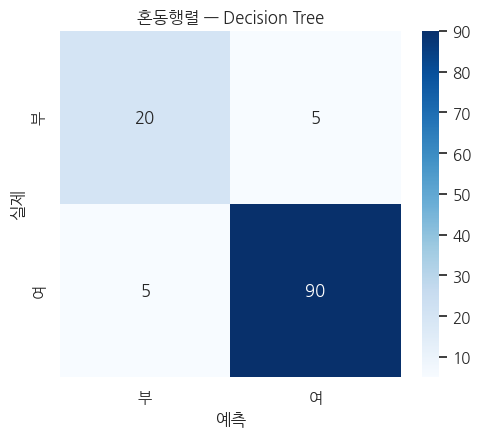

In [37]:
모델_목록 = ["Logistic/Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting", "K Nearest Neighbor"]
교차검증 = False
불균형_보정 = True        # 분류에서 적은 범주에 가중치(class_weight="balanced") — 적은 범주를 놓치지 않게
정렬_기준 = None          # None = 분류 "F1", 회귀 "R2" (예: "AUC", "Accuracy", "MAE", "RMSE")

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import cross_val_score
from sklearn import metrics as M

분류 = 유형_ == "분류"
cw = {"class_weight": "balanced"} if 분류 and 불균형_보정 else {}
모델_정의 = {
    "Logistic/Linear Regression": LogisticRegression(max_iter=2000, **cw) if 분류 else LinearRegression(),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=난수_시드, **cw) if 분류 else DecisionTreeRegressor(max_depth=8, random_state=난수_시드),
    "Random Forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=난수_시드, **cw) if 분류 else RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=난수_시드),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=난수_시드, **(cw if "class_weight" in HistGradientBoostingClassifier().get_params() else {})) if 분류 else HistGradientBoostingRegressor(random_state=난수_시드),
    "K Nearest Neighbor": (KNeighborsClassifier if 분류 else KNeighborsRegressor)(n_neighbors=15),
}
표준화_모델 = {"Logistic/Linear Regression", "K Nearest Neighbor"}     # 거리·계수 기반 모델은 표준화한 입력을 쓴다


def 평가(y, p, prob=None):
    if 분류:
        avg = "binary" if len(클래스) == 2 else "macro"
        r = {"Accuracy": M.accuracy_score(y, p), "Precision": M.precision_score(y, p, average=avg, zero_division=0),
             "Recall": M.recall_score(y, p, average=avg, zero_division=0), "F1": M.f1_score(y, p, average=avg, zero_division=0)}
        if prob is not None:
            r["AUC"] = M.roc_auc_score(y, prob[:, 1]) if len(클래스) == 2 else M.roc_auc_score(y, prob, multi_class="ovr")
        return r
    mse = M.mean_squared_error(y, p)
    return {"MAE": M.mean_absolute_error(y, p), "MSE": mse, "RMSE": mse ** .5, "R2": M.r2_score(y, p)}


결과, 학습된모델 = {}, {}
for name in 모델_목록:
    m = 모델_정의[name]
    tr, te = (Xs_train, Xs_test) if name in 표준화_모델 else (X_train, X_test)
    m.fit(tr, y_train)
    r = 평가(y_test, m.predict(te), m.predict_proba(te) if 분류 and hasattr(m, "predict_proba") else None)
    if 교차검증:
        r["CV(5-fold)"] = cross_val_score(m, tr, y_train, cv=5, scoring="accuracy" if 분류 else "r2").mean()
    결과[name], 학습된모델[name] = r, m

기준 = 정렬_기준 or ("F1" if 분류 else "R2")
작을수록좋음 = 기준 in ("MAE", "MSE", "RMSE")
표 = pd.DataFrame(결과).T.sort_values(기준, ascending=작을수록좋음)
최고모델_이름 = 표.index[0]
최고모델 = 학습된모델[최고모델_이름]
try:
    import piplite
    await piplite.install("jinja2")  # pandas .style 에 필요(없으면 색칠 없이 표만 출력)
except Exception:
    pass
try:
    display(표.round(4).style.highlight_max(axis=0, color="#d6ecd2") if not 작을수록좋음 else 표.round(4))
except Exception:
    display(표.round(4))
print(f"정렬 기준 {기준} 1위: {최고모델_이름}")
_best = 표.iloc[0]["Accuracy" if 분류 else "R2"]
if _best >= 0.995:                                  # 거의 완벽하면 정답을 계산할 수 있는 컬럼(누수)이 입력에 있는지 의심
    m = next((학습된모델[k] for k in (최고모델_이름, "Random Forest", "Decision Tree") if k in 학습된모델 and hasattr(학습된모델[k], "feature_importances_")), None)
    imp = pd.Series(m.feature_importances_ if m is not None else np.abs(np.atleast_2d(학습된모델[최고모델_이름].coef_)).mean(0), index=특성이름)
    print(f"⚠ {'Accuracy' if 분류 else 'R2'} {_best:.4f} — 거의 완벽합니다. 종속을 계산하거나 결과 뒤에 기록되는 컬럼이 입력에 있는지 확인하세요. "
          f"영향 큰 입력: {list(imp.sort_values(ascending=False).index[:3])}  → 3번 셀 `제외` 에 넣어 다시 실행")

te = Xs_test if 최고모델_이름 in 표준화_모델 else X_test
p = 최고모델.predict(te)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
if 분류:
    sns.heatmap(M.confusion_matrix(y_test, p), annot=True, fmt="d", cmap="Blues", xticklabels=클래스, yticklabels=클래스, ax=ax)
    ax.set(xlabel="예측", ylabel="실제", title=f"혼동행렬 — {최고모델_이름}")
else:
    ax.scatter(y_test, p, s=8, alpha=.4)
    lim = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]
    ax.plot(lim, lim, "r--")
    ax.set(xlabel="실제", ylabel="예측", title=f"실제 vs 예측 — {최고모델_이름}")
plt.show()

## 5. 딥러닝 — 완전연결 신경망
`은닉층` 의 숫자가 층마다 노드 수입니다. 검증 손실이 `조기종료` 번 동안 나아지지 않으면 멈추고, 가장 좋았던 가중치로 돌아갑니다.
tensorflow 가 없으면 scikit-learn 신경망(MLP)으로 같은 구조를 학습합니다.

딥러닝(scikit-learn MLP) 학습 25 epoch — 테스트: {'Accuracy': 0.8417, 'Precision': 0.9419, 'Recall': 0.8526, 'F1': 0.895, 'AUC': 0.9465}


,Accuracy,Precision,Recall,F1,AUC
Logistic/Linear Regression,0.8750,0.9651,0.8737,0.9171,0.9688
Decision Tree,0.9167,0.9474,0.9474,0.9474,0.8737
Random Forest,0.9083,0.9286,0.9579,0.9430,0.9752
Gradient Boosting,0.9167,0.9775,0.9158,0.9457,0.9806
K Nearest Neighbor,0.8750,0.8704,0.9895,0.9261,0.8949
딥러닝,0.8417,0.9419,0.8526,0.8950,0.9465


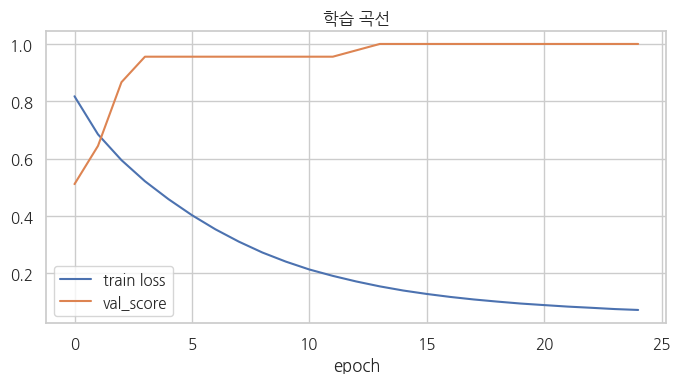

In [38]:
은닉층 = [64, 32]        # 층마다 노드 수
활성함수 = "relu"         # "relu" | "tanh" | "sigmoid"
드롭아웃 = 0.2
에폭 = 200                # 최대 학습 횟수(조기종료가 알맞은 때 멈춘다)
배치 = 64
학습률 = 0.001
조기종료 = 10

if tf is not None:
    tf.random.set_seed(난수_시드)
    출력 = len(클래스) if 분류 else 1
    층 = [tf.keras.Input(shape=(Xs_train.shape[1],))]
    for u in 은닉층:
        층 += [tf.keras.layers.Dense(u, activation=활성함수), tf.keras.layers.Dropout(드롭아웃)]
    층.append(tf.keras.layers.Dense(출력, activation="softmax" if 분류 else "linear"))
    딥모델 = tf.keras.Sequential(층)
    딥모델.compile(optimizer=tf.keras.optimizers.Adam(학습률),
                 loss="sparse_categorical_crossentropy" if 분류 else "mse", metrics=["accuracy"] if 분류 else ["mae"])
    가중 = None
    if 분류 and 불균형_보정:                          # 4번 셀 불균형_보정 과 같은 class_weight
        cnt = np.bincount(y_train, minlength=len(클래스))
        가중 = {i: len(y_train) / (len(클래스) * max(n, 1)) for i, n in enumerate(cnt)}
    hist = 딥모델.fit(Xs_train, y_train, validation_split=0.2, epochs=에폭, batch_size=배치, verbose=0, class_weight=가중,
                    callbacks=[tf.keras.callbacks.EarlyStopping(patience=조기종료, restore_best_weights=True)])
    기록 = hist.history
    딥_예측 = lambda X: (딥모델.predict(X, verbose=0) if 분류 else 딥모델.predict(X, verbose=0).ravel())
else:
    from sklearn.neural_network import MLPClassifier, MLPRegressor
    Xd, yd = Xs_train, y_train
    if 분류 and 불균형_보정:                          # MLP 는 class_weight 가 없어 적은 범주 행을 복제해 균형을 맞춘다
        _r = np.random.default_rng(난수_시드)
        _cnt = np.bincount(y_train)
        _idx = np.concatenate([_r.choice(np.where(y_train == k)[0], _cnt.max(), replace=True) if 0 < n < _cnt.max()
                               else np.where(y_train == k)[0] for k, n in enumerate(_cnt)])
        Xd, yd = Xs_train[_idx], y_train[_idx]
    딥모델 = (MLPClassifier if 분류 else MLPRegressor)(hidden_layer_sizes=tuple(은닉층), activation={"sigmoid": "logistic"}.get(활성함수, 활성함수),
                                                   learning_rate_init=학습률, batch_size=배치, max_iter=에폭, early_stopping=True,
                                                   n_iter_no_change=조기종료, random_state=난수_시드).fit(Xd, yd)
    기록 = {"loss": 딥모델.loss_curve_, "val_score": list(딥모델.validation_scores_)}
    딥_예측 = lambda X: (딥모델.predict_proba(X) if 분류 else 딥모델.predict(X))

out = 딥_예측(Xs_test)
딥_결과 = 평가(y_test, out.argmax(1), out) if 분류 else 평가(y_test, out)
print(f"딥러닝({딥러닝_도구}) 학습 {len(기록['loss'])} epoch — 테스트:", {k: round(v, 4) for k, v in 딥_결과.items()})
display(pd.DataFrame({**결과, "딥러닝": 딥_결과}).T.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(기록["loss"], label="train loss")
for k in ("val_loss", "val_score"):
    if k in 기록:
        ax.plot(기록[k], label=k)
ax.set(xlabel="epoch", title="학습 곡선")
ax.legend()
plt.show()

## 6. 변수 영향도
- **모델 내장 중요도**: 트리 모델(Random Forest 등)의 `feature_importances_`, 선형 모델은 계수 크기. 원-핫으로 나뉜 범주 컬럼은 원래 컬럼으로 합쳐서 봅니다.
- **순열 중요도(permutation)**: 한 컬럼 값을 섞었을 때 성능이 얼마나 떨어지는지 — 어떤 모델(딥러닝 포함)에도 쓸 수 있습니다.

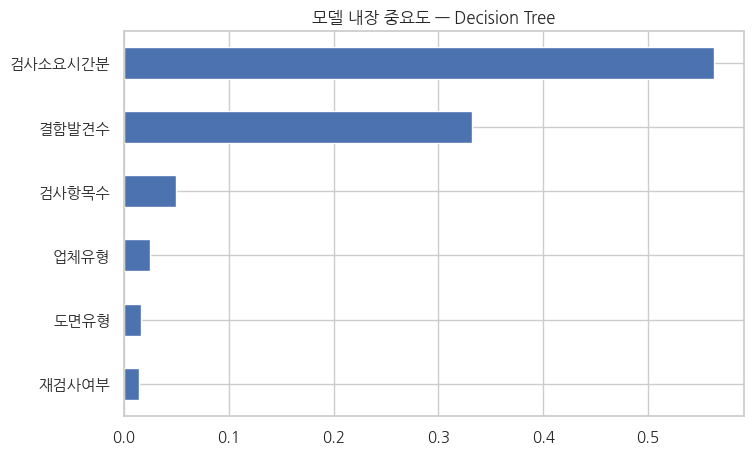

Decision Tree 기준 점수(Accuracy) 0.9167 — 컬럼 값을 섞었을 때 떨어지는 정도


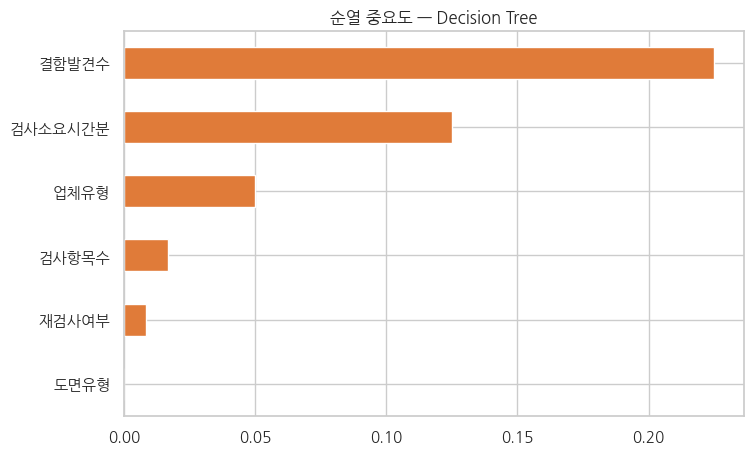

,결함발견수,검사소요시간분,업체유형,검사항목수,재검사여부,도면유형
점수 하락,0.225,0.125,0.05,0.0167,0.0083,0.0


In [39]:
대상_모델 = None          # None = 4번 최고 모델, 예: "Random Forest" 또는 "딥러닝"
상위_개수 = 15
순열_최대행수 = 3000


def 원래컬럼(특성):
    for c in 범주입력:
        if 특성.startswith(f"{c}_"):
            return c
    return 특성


이름 = 대상_모델 or 최고모델_이름
if 이름 != "딥러닝":
    m = 학습된모델[이름]
    if hasattr(m, "feature_importances_"):
        imp = pd.Series(m.feature_importances_, index=특성이름)
    elif hasattr(m, "coef_"):
        imp = pd.Series(np.abs(np.atleast_2d(m.coef_)).mean(0), index=특성이름)
    else:
        imp = None
    if imp is not None:
        내장 = imp.groupby(imp.index.map(원래컬럼)).sum().sort_values(ascending=False)
        내장.head(상위_개수).sort_values().plot.barh(figsize=(8, 5), title=f"모델 내장 중요도 — {이름}")
        plt.show()

# 순열 중요도: 원래 컬럼 단위로 값을 섞는다(원-핫 열을 함께)
rng = np.random.default_rng(난수_시드)
sub = rng.choice(len(X_test), min(len(X_test), 순열_최대행수), replace=False)
Xb, yb = X_test.iloc[sub], y_test[sub]


def 점수(X):
    Xs = scaler.transform(X)
    if 이름 == "딥러닝":
        o = 딥_예측(Xs)
        return M.accuracy_score(yb, o.argmax(1)) if 분류 else M.r2_score(yb, o)
    m = 학습된모델[이름]
    o = m.predict(Xs if 이름 in 표준화_모델 else X)
    return M.accuracy_score(yb, o) if 분류 else M.r2_score(yb, o)


기준점수 = 점수(Xb)
순열 = {}
for c in 입력:
    cols = [f for f in 특성이름 if 원래컬럼(f) == c]
    Xp = Xb.copy()
    Xp[cols] = Xb[cols].to_numpy()[rng.permutation(len(Xb))]
    순열[c] = 기준점수 - 점수(Xp)
순열 = pd.Series(순열).sort_values(ascending=False)
print(f"{이름} 기준 점수({'Accuracy' if 분류 else 'R2'}) {기준점수:.4f} — 컬럼 값을 섞었을 때 떨어지는 정도")
순열.head(상위_개수).sort_values().plot.barh(figsize=(8, 5), color="#e07b39", title=f"순열 중요도 — {이름}")
plt.show()
display(순열.round(4).to_frame("점수 하락").head(상위_개수).T)

## 7. 시뮬레이션 — 테스트 데이터 몇 개로 예측해 보기
테스트 데이터에서 `샘플_수` 개를 자동으로 뽑아 입력값·실제값·머신러닝 예측·딥러닝 예측을 나란히 보여 줍니다.
`바꿔보기` 에 `{"컬럼": 값}` 을 쓰면 첫 번째 샘플의 값을 바꿨을 때 예측이 어떻게 달라지는지도 봅니다.

In [40]:
샘플_수 = 5
바꿔보기 = {}          # 예: {"단가편차율(%)": -25, "업체규모": "소상공인"}  (첫 번째 샘플에 적용)

샘플_idx = pd.Index(idx_test).to_series().sample(샘플_수, random_state=난수_시드).index
원본 = df.loc[샘플_idx, 입력 + [종속]]


def 예측(raw):
    X = 입력_변환(raw)
    Xs = scaler.transform(X)
    ml = 최고모델.predict(Xs if 최고모델_이름 in 표준화_모델 else X)
    dl = 딥_예측(Xs)
    if 분류:
        return pd.DataFrame({f"ML 예측({최고모델_이름})": [클래스[i] for i in ml],
                             "DL 예측": [클래스[i] for i in dl.argmax(1)], "DL 확률": dl.max(1).round(3)}, index=raw.index)
    return pd.DataFrame({f"ML 예측({최고모델_이름})": np.round(ml, 3), "DL 예측": np.round(dl, 3)}, index=raw.index)


결과표 = 원본.rename(columns={종속: f"실제 {종속}"}).join(예측(원본))
display(결과표)

if 바꿔보기:
    확인(list(바꿔보기), 입력, "바꿔보기 컬럼")
    전 = 원본.iloc[[0]]
    후 = 전.copy()
    for c, v in 바꿔보기.items():
        후[c] = v
    비교 = pd.concat([전.assign(구분="바꾸기 전"), 후.assign(구분="바꾼 뒤")]).set_index("구분")
    display(비교[list(바꿔보기)].join(pd.concat([예측(전), 예측(후)]).set_index(비교.index)))

,도면유형,업체유형,검사항목수,검사소요시간분,결함발견수,재검사여부,실제 합격여부,ML 예측(Decision Tree),DL 예측,DL 확률
182,전개도,중소기업,9,33,5,부,여,여,여,0.969
11,부품도,중소기업,16,6,5,부,여,여,여,0.995
125,부품도,중소기업,35,28,4,부,여,여,여,0.965
288,부품도,일반업체,39,44,4,부,여,여,부,0.624
386,조립도,특수계약업체,25,41,7,부,여,여,여,0.518
